# Do code-model maps track search order or storage? (TP-G2 demo)

**The question.** Earlier rounds of this research line read the geometry of a code LLM's program states as a
"path-search manifold": BFS programs in one region, DFS in another, A* in a third. This experiment (iteration 10,
TP-G2) tests whether that geometry really separates programs by **expansion discipline**, the order in which a
search expands grid cells:
- FIFO / level order (BFSO), LIFO / depth order (DFSO), goal-heuristic order (HEUR), path-cost order (COST),
  relaxation sweeps (RELAX) and random order (RAND);

once the **storage container** is held fixed by design:
- deque, list, recursion (CALL), heapq, 2-D arrays (GRID2D) or set.

**What the full experiment did.** `method.py` orchestrates every stage, and all the code lives in `src/`.
1. **Generate.** Qwen3-32B (OpenRouter, thinking off) wrote name-scrubbed grid path programs for a pre-committed
   6 × 6 discipline × container factorial: 24 implementable cells with 12 verified programs each, 287 programs in
   all. The prompts name no algorithm. Every program passed two hidden test suites, an AST container check and a
   discipline check (tracer, runtime probes and hand reads).
2. **States.** Each program was teacher-forced through Qwen3-8B (bf16, block 17) and Qwen3-32B (NF4, block 33). The
   readout is **R1**, the mean hidden state over the code tokens.
3. **G1** is representational-similarity analysis. Partial Spearman correlations of the program-state RDM with the
   discipline RDM given the container RDM (**ρ_dc**), and the reverse (**ρ_cd**). Inference uses program bootstraps
   and within-stratum permutations, alongside baselines and pre-registered sensitivities.
4. **G2** is out-of-sample placement. A prompt that **banned the five usual answers** (BFS, DFS, IDDFS, A*,
   greedy best-first) made models write other programs ("survivor families": unit-weight Dijkstra, grid
   Bellman-Ford, coordinate-key heaps, random frontiers, raster sweeps, set frontiers), plus covert BFS/DFS under
   other names. These programs are placed out of sample on a kNN-geodesic frame built from the factorial cells.
   Do they land at the **edge** of the banned region, or on the **opposite** side?

**What this notebook runs.** The analysis stages of `method.py all-analysis`: tests T7/T8, `g1`, `g2`, `robust`,
`outputs`, `figures` and `audit`. The original `src/` code is copied cell by cell and runs on a curated subset of 72
factorial programs (3 per cell) and 28 placed survivor programs, with their precomputed Qwen3-8B and Qwen3-32B
states. The LLM generation (OpenRouter) and the GPU state extraction are **not** rerun; their outputs come from
`mini_demo_data.json`.

**Full-run headline (287 programs).**
- Discipline given container: ρ_dc = 0.226 (8B) and 0.285 (32B).
- Container given discipline is larger: ρ_cd = 0.300 and 0.414.
- **Verdict: INDETERMINATE.** There is a real discipline signal (permutation p = 0.0005, above the bag-of-tokens and
  random-network baselines), but container and token surface are encoded more strongly.
- **G2:** survivor families land with their own discipline; covert BFS/DFS land on banned classes 99% / 98% of the
  time.
- Geometry is correlational: no causal or steering claim is made.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab, always install (the original src/ code logs with loguru)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib: pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
# One BLAS thread per process, as in method.py / src/analysis.py (multithreaded BLAS made G1 ~40x slower on 6 CPUs)
import os

for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_v] = "1"

# ---- original imports of src/g1.py, g2.py, geometry.py, analysis.py, verify.py, outputs.py, figures.py and
#      audit/rederive.py (merged; `from __future__ import annotations` is not needed on Python 3.12)
import ast
import csv
import io
import json
import math
import multiprocessing as mp
import re
import statistics
import sys
import time
import tokenize
import warnings
from collections import Counter, defaultdict
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
from typing import Any

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from loguru import logger
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import binomtest, kendalltau, rankdata, spearmanr

# ---- notebook additions
import http.client
import urllib.request
from types import SimpleNamespace

# logging as in method.py main(): INFO lines to stdout
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

1

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-10/experiment-55/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# Guard: until this demo is pushed, the URL can still serve an older file pushed to the same path (another demo's
# data); use the GitHub copy only if it is this artifact's demo data.
if not str(data.get("metadata", {}).get("source_artifact", "")).startswith("art_ho7tqaOyBjkN"):
    print("The GitHub copy is not this artifact's demo data; using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
EXAMPLES = data["datasets"][0]["examples"]
print(data["metadata"]["description"])
print("dataset:", data["datasets"][0]["dataset"], "| examples by role:", dict(Counter(e["role"] for e in EXAMPLES)),
      "| placed families:", data["metadata"]["selection"]["placed_families"])

The GitHub copy is not this artifact's demo data; using local mini_demo_data.json
TP-G2 demo subset: 72 frozen factorial programs (3 per discipline x container cell) and 28 placed survivor-family programs, with their teacher-forced program states (Qwen3-8B bf16 block 17 / Qwen3-32B NF4 block 33 and the layer, readout, E0, RANDNET and second-context arrays the analysis uses).
dataset: tpg2_demo_programs | examples by role: {'factorial': 72, 'placed': 28} | placed families: {'F-UD': 7, 'F-BF': 7, 'F-COV': 8, 'F-CK': 2, 'F-RF': 2, 'F-RS': 1, 'F-SF': 1}


## Configuration

Every tunable count of the original analysis is set here, with its original (full-run) value in the comment. The
values below **are the original counts**. On the mini data the whole notebook runs in about two minutes on a
2-CPU machine, most of it T7's 200 synthetic null datasets. The test runs started from the minimum
(`N_PER_CELL = 1`, 10 resamples, 2 null datasets) and scaled up.

Two settings are tied to the size of the mini data:
- `N_PER_CELL` can be at most 3, because the mini data holds 3 programs per cell (the full run has 12). Lower it
  for a faster, noisier run.
- `CLASS_FLOOR` drops from 10 to `N_PER_CELL`. The full-run frame keeps classes with at least 10 programs; here a
  class (one cell) has `N_PER_CELL` programs.

`K_PRIMARY` / `K_SECOND` keep their frozen values (15 and 10).

In [5]:
# ---- Demo scale. Original full-run values in the comments.
N_PER_CELL = 3            # factorial programs per cell (mini data holds 3 per cell; full run: 12)
TAGS = ["8b", "32b"]      # models analysed (full run: both)
N_BOOT = 1000             # G1 program-bootstrap resamples (original: 1000)
N_PERM = 2000             # G1 restricted permutations per statistic (original: 2000)
N_BOOT_VARIANTS = 200     # bootstrap resamples per sensitivity variant S3-S10 (original: 200)
N_BOOT_RANKREG = 100      # bootstrap resamples of the S2 rank regression (original: 100)
N_BOOT_FAMILY = 1000      # family bootstrap of r_F on the full frame (original: 1000)
N_BOOT_HELD_FIXED = 500   # family bootstrap on the held-fixed sub-frames (original: 500)
N_BOOT_ROBUST = 200       # family bootstrap inside the robustness grid (original: 200)
N_PLACEBO = 1000          # family-shuffle placebo draws (original: 1000)
T7_N_NULL = 200           # synthetic null datasets in test T7 (original: 200)
K_PRIMARY, K_SECOND = 15, 10   # kNN graph sizes (frozen in src/v10.py; unchanged)
CLASS_FLOOR = N_PER_CELL  # min programs per frame class (original: 10 with 12 programs per cell)

## The pipeline: `method.py`

`method.py` is the experiment's stage orchestrator. Each stage is one or more subprocess calls into `src/`,
`tests/`, `scripts/` or `audit/`, and `python method.py all-analysis` runs `g1 → g2 → robust → outputs → figures →
audit`. The cell below copies its stage table unchanged.

Its `main()` shells out to those scripts, so it is not run here. Instead, the notebook copies the code of each
analysis stage into cells and runs it in place. The printout says how each stage is covered.

In [6]:
ROOT = Path(".").resolve()          # method.py: ROOT = Path(__file__).resolve().parent
PY = sys.executable

STAGES: dict[str, list[list[str]]] = {
    "setup": [["python3", "scripts/setup_inputs.py"]],
    "r0": [[PY, "src/r0.py"]],
    "tests": [[PY, "tests/test_verifiers.py"], [PY, "tests/test_analysis.py"]],
    "generate": [[PY, "src/gen.py", "smoke"], [PY, "src/gen.py", "pilot"], [PY, "src/gen.py", "main"],
                 [PY, "src/gen.py", "paraphrase"]],
    "assemble": [[PY, "src/assemble.py"]],
    "freeze": [[PY, "src/freeze.py", "factorial"], [PY, "src/freeze.py", "topups"]],
    "states": [[PY, "src/extract.py", "8b", "repro", "placed", "refs", "factorial", "factorial_ctx2", "topups"],
               [PY, "src/extract.py", "randnet", "factorial"],
               [PY, "src/extract.py", "32b", "repro", "placed", "refs", "factorial", "topups"]],
    "order": [[PY, "scripts/order_matrix.py"]],
    "g1": [[PY, "src/analysis.py", "g1", "8b", "32b"]],
    "g2": [[PY, "src/analysis.py", "g2", "8b", "32b"]],
    "robust": [[PY, "src/analysis.py", "robust", "8b", "32b"]],
    "outputs": [[PY, "src/outputs.py"]],
    "figures": [[PY, "src/figures.py"]],
    "audit": [["python3", "-I", "audit/rederive.py"]],
}
STAGES["all-analysis"] = STAGES["g1"] + STAGES["g2"] + STAGES["robust"] + STAGES["outputs"] + STAGES["figures"] + \
    STAGES["audit"]

# Notebook addition: how each stage is covered here (method.py main() runs every command above as a subprocess).
IN_THIS_NOTEBOOK = {
    "setup": "not needed: everything this demo reads ships in mini_demo_data.json",
    "r0": "not run: the reproduction gate needs iteration 9's frozen M-code states",
    "tests": "T7 + T8 (tests/test_analysis.py) run below; the verifier tests need the vendored suites",
    "generate": "precomputed: the programs (Qwen3-32B via OpenRouter) are in mini_demo_data.json",
    "assemble": "precomputed: the placed survivor families are in mini_demo_data.json",
    "freeze": "precomputed: this demo uses a subset of the frozen sets",
    "states": "precomputed: Qwen3-8B / Qwen3-32B / RANDNET states (GPU) are in mini_demo_data.json",
    "order": "precomputed: expansion-order matrix rows ship with every factorial program",
    "g1": "runs below (src/g1.py + src/analysis.py run_g1)",
    "g2": "runs below (src/g2.py + src/analysis.py run_g2); frame = the 24 factorial cells",
    "robust": "runs below (src/analysis.py robustness)",
    "outputs": "placebos + G1 verdict run below (src/outputs.py)",
    "figures": "F1, F2 and F4-F8 run below (src/figures.py)",
    "audit": "the stdlib re-derivation runs below (audit/rederive.py)",
}
for st, cmds in STAGES.items():
    if st != "all-analysis":
        print(f"{st:<9}| {' ; '.join(' '.join(c[1:]) for c in cmds)[:58]:<58} | {IN_THIS_NOTEBOOK[st]}")

setup    | scripts/setup_inputs.py                                    | not needed: everything this demo reads ships in mini_demo_data.json
r0       | src/r0.py                                                  | not run: the reproduction gate needs iteration 9's frozen M-code states
tests    | tests/test_verifiers.py ; tests/test_analysis.py           | T7 + T8 (tests/test_analysis.py) run below; the verifier tests need the vendored suites
generate | src/gen.py smoke ; src/gen.py pilot ; src/gen.py main ; sr | precomputed: the programs (Qwen3-32B via OpenRouter) are in mini_demo_data.json
assemble | src/assemble.py                                            | precomputed: the placed survivor families are in mini_demo_data.json
freeze   | src/freeze.py factorial ; src/freeze.py topups             | precomputed: this demo uses a subset of the frozen sets
states   | src/extract.py 8b repro placed refs factorial factorial_ct | precomputed: Qwen3-8B / Qwen3-32B / RANDNET states (GPU) are in

## Shared constants (`src/v10.py`)

The banned / non-banned split defines G2. The five-name ban forbade BFS, DFS, IDDFS, A* and greedy best-first, so
the BFSO, DFSO and HEUR cells count as **banned** and the COST, RELAX and RAND cells as **non-banned**. The model
table fixes the readout blocks: Qwen3-8B block 17 and Qwen3-32B block 33.

The original code imports its modules (`v10`, `g1`, `g2`, `geometry`, `verify`, `analysis`) and calls them as
`v10.MODELS[tag]`, `geometry.geodesics(X, k)` and so on. Here each module's code runs at the top level of the
notebook, and `bundle(...)` gathers its objects under the original module name. The copied call sites therefore run
unchanged.

In [7]:
def bundle(*objs: Any, **named: Any) -> SimpleNamespace:
    """Notebook helper: gather one src/ module's objects under its original module name."""
    return SimpleNamespace(**{o.__name__: o for o in objs}, **named)


# src/v10.py: paths, frozen settings, the banned / non-banned split, model pins and block choices.
# (The sha256 commitment chain, commit() / verify_chain(), guarded the pre-registration; rerunning does not need it.)
RESULTS, FIGS = ROOT / "results", ROOT / "figures"
STATES_V10 = ROOT / "cache" / "states_v10"
for _d in (RESULTS, FIGS, STATES_V10):
    _d.mkdir(parents=True, exist_ok=True)

CANON = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]
BANNED_ALGS = ["bfs", "dfs", "iddfs", "astar", "gbfs"]
NONBANNED_ALGS = ["dijkstra_unit", "idastar", "bibfs", "jps", "biastar"]
BANNED_DISC = ["BFSO", "DFSO", "HEUR"]
NONBANNED_DISC = ["COST", "RELAX", "RAND"]
# CLASS_FLOOR = 10 and K_PRIMARY, K_SECOND = 15, 10 are set in the config cell

M8 = {"tag": "8b", "repo": "Qwen/Qwen3-8B", "revision": "b968826d9c46dd6066d109eabc6255188de91218",
      "precision": "bf16", "n_layers": 36, "n_keep": 27, "blocks": [9, 11, 13, 15, 17, 19, 21, 23, 25, 26],
      "primary_block": 17, "hidden": 4096, "engine": "HF bf16 Qwen3-8B"}
M32 = {"tag": "32b", "repo": "unsloth/Qwen3-32B-bnb-4bit", "revision": "7f721e74a6a8cc9ee352f7e49303a2c1705f9083",
       "precision": "nf4", "n_layers": 64, "n_keep": 40, "blocks": [21, 25, 29, 31, 33, 35, 37, 39],
       "primary_block": 33, "hidden": 5120, "engine": "HF nf4 unsloth/Qwen3-32B-bnb-4bit truncated"}
MODELS = {"8b": M8, "32b": M32}
READOUTS = ["R1", "R1g", "R2", "R3"]


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + f".tmp{os.getpid()}")
    tmp.write_text(json.dumps(obj, indent=indent, ensure_ascii=False, default=_default))
    tmp.replace(p)


def _default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


v10 = bundle(write_json, read_json, ROOT=ROOT, RESULTS=RESULTS, FIGS=FIGS, STATES_V10=STATES_V10, CANON=CANON,
             BANNED_ALGS=BANNED_ALGS, NONBANNED_ALGS=NONBANNED_ALGS, BANNED_DISC=BANNED_DISC,
             NONBANNED_DISC=NONBANNED_DISC, CLASS_FLOOR=CLASS_FLOOR, K_PRIMARY=K_PRIMARY, K_SECOND=K_SECOND, M8=M8,
             M32=M32, MODELS=MODELS, READOUTS=READOUTS)
print({t: (m["repo"], m["precision"], "primary block", m["primary_block"], "hidden", m["hidden"])
       for t, m in v10.MODELS.items()})

{'8b': ('Qwen/Qwen3-8B', 'bf16', 'primary block', 17, 'hidden', 4096), '32b': ('unsloth/Qwen3-32B-bnb-4bit', 'nf4', 'primary block', 33, 'hidden', 5120)}


## From `mini_demo_data.json` to the arrays the code expects

The original analysis reads three kinds of file:
- `cache/states_v10/<model>_<set>.npz`: `R` (programs × 4 readouts × blocks × hidden, float16), `E0`, `uids` and
  `blocks`;
- the matching `.jsonl` index, which holds each program's context variant and number of code tokens;
- the frozen program sets `data/factorial_set.jsonl` and `data/placed_programs.jsonl`.

This cell rebuilds those structures from `data` as `STATES`, `INDEX` and `ROWS`. The loader functions below change
only their file reads; their bodies are otherwise the original.

**How the states are stored.** Raw float16 states for 100 programs over every readout and block of two models would
take more than 100 MB. `build_mini_demo_data.py` therefore stores every state array (one model × readout × block, or
E0 / RANDNET / the second context) in an **exact isometric basis** of the selected programs' own states:
- If `M` is the programs × hidden matrix, with thin SVD `M = U S Vᵀ`, the file stores `U S`.
- Since `(US)(US)ᵀ = M Mᵀ`, every inner product, norm, cosine distance and Euclidean distance is unchanged.
- So is everything built on them: RDMs, kNN graphs, geodesics, PCA variance, Isomap and MDS.
- The rounding to 9 significant digits gives a relative error below 1e-8.

A state therefore has 100 (or 72) coordinates instead of 4,096 / 5,120, but it describes the same point
configuration. The arrays that the factorial and placed programs share (R1 / R1g / R2 at the primary block) were
factorised jointly, so the out-of-sample placement distances are exact as well.

In [8]:
META = data["metadata"]

# The first N_PER_CELL programs of every cell (the mini data holds 3 per cell), then the placed survivor programs
_per_cell = Counter()
FAC_EX = []
for e in EXAMPLES:
    if e["role"] == "factorial" and _per_cell[e["cell"]] < N_PER_CELL:
        _per_cell[e["cell"]] += 1
        FAC_EX.append(e)
PL_EX = [e for e in EXAMPLES if e["role"] == "placed"]
_FAC_POS = {e["uid"]: i for i, e in enumerate(e for e in EXAMPLES if e["role"] == "factorial")}


def states_npz(exs: list[dict], prefix: str, blocks: list[int], readouts: list[str] = READOUTS,
               e0_key: str | None = None) -> dict[str, np.ndarray]:
    """Rebuild one cache/states_v10/<model>_<set>.npz as a dict (R: n x readouts x blocks x D, E0, uids, blocks).
    Readout / block pairs that the mini data does not ship are NaN (the analysis never reads them); shorter
    coordinate vectors are zero-padded to D, which leaves every inner product and distance unchanged."""
    have = [(ri, bi, f"{prefix}|{ro}|{b}") for ri, ro in enumerate(readouts) for bi, b in enumerate(blocks)
            if f"{prefix}|{ro}|{b}" in exs[0]["states"]]
    D = max(len(exs[0]["states"][k]) for _, _, k in have)
    R = np.full((len(exs), len(readouts), len(blocks), D), np.nan)
    for ri, bi, k in have:
        V = np.array([e["states"][k] for e in exs], dtype=np.float64)
        R[:, ri, bi, :] = 0.0
        R[:, ri, bi, :V.shape[1]] = V
    E0 = np.array([e["states"][e0_key] for e in exs], dtype=np.float64) if e0_key else np.full((len(exs), 1), np.nan)
    return {"R": R, "E0": E0, "uids": np.array([e["uid"] for e in exs]), "blocks": np.array(blocks),
            "readouts": np.array(readouts)}


STATES: dict[str, dict[str, np.ndarray]] = {}       # replaces cache/states_v10/<model>_<set>.npz
INDEX: dict[str, list[dict]] = {}                   # replaces cache/states_v10/<model>_<set>.jsonl
for tag in ("8b", "32b"):
    STATES[f"{tag}_factorial"] = states_npz(FAC_EX, tag, META["blocks"][tag], e0_key=f"{tag}|E0")
    STATES[f"{tag}_placed"] = states_npz(PL_EX, tag, META["blocks"][tag])
    INDEX[f"{tag}_factorial"] = [{"uid": e["uid"], "context_variant": e["context_variant"],
                                  "n_code_tokens": e["n_code_tokens"][tag]} for e in FAC_EX]
    INDEX[f"{tag}_placed"] = [{"uid": e["uid"]} for e in PL_EX]
STATES["8b_factorial_ctx2"] = states_npz(FAC_EX, "8b_ctx2", META["blocks"]["8b"])    # second neutral-twin context
STATES["randnet_factorial"] = states_npz(FAC_EX, "randnet", [17], readouts=["R1"])  # random-init Qwen3-8B, block 17
STATES["order_matrix_factorial"] = {                                                # replaces data/order_matrix_factorial.npz
    "D": np.array([[e["order_D_row"][_FAC_POS[f["uid"]]] for f in FAC_EX] for e in FAC_EX]),
    "uids": np.array([e["uid"] for e in FAC_EX])}
ROWS = {"factorial_set": [dict(e, scrubbed=e["output"]) for e in FAC_EX],         # replaces data/factorial_set.jsonl
        "placed_programs": [dict(e, scrubbed=e["output"]) for e in PL_EX]}       # replaces data/placed_programs.jsonl

for name, z in STATES.items():
    print(f"{name:<24}", {k: v.shape for k, v in z.items() if k in ("R", "E0", "D")})

8b_factorial             {'R': (72, 4, 10, 100), 'E0': (72, 72)}
8b_placed                {'R': (28, 4, 10, 100), 'E0': (28, 1)}
32b_factorial            {'R': (72, 4, 8, 100), 'E0': (72, 72)}
32b_placed               {'R': (28, 4, 8, 100), 'E0': (28, 1)}
8b_factorial_ctx2        {'R': (72, 4, 10, 72), 'E0': (72, 1)}
randnet_factorial        {'R': (72, 1, 1, 72), 'E0': (72, 1)}
order_matrix_factorial   {'D': (72, 72)}


The builder also recorded a few norms and cosines computed from the **raw** float16 states, which are not shipped.
Recomputing them from the stored coordinates checks the claim above: the differences should sit at float-rounding
level.

In [9]:
print(f"{'array':<11}{'quantity':<11}{'raw float16':>15}{'stored coords':>15}{'abs diff':>10}")
for c in META["storage_check"]:
    V = np.array([e["states"][c["key"]] for e in EXAMPLES if c["key"] in e["states"]])
    if c["j"] is None:
        what, raw, got = f"|x{c['i']}|", c["raw_norm"], float(np.linalg.norm(V[c["i"]]))
    else:
        a, b = V[c["i"]], V[c["j"]]
        what, raw = f"cos({c['i']},{c['j']})", c["raw_cosine"]
        got = float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))
    print(f"{c['key']:<11}{what:<11}{raw:>15.8f}{got:>15.8f}{abs(raw - got):>10.1e}")

array      quantity       raw float16  stored coords  abs diff
8b|R1|17   |x0|           59.77229025    59.77229022   3.1e-08
8b|R1|17   |x1|           60.13828190    60.13828187   3.4e-08
8b|R1|17   |x72|          59.69327614    59.69327615   6.8e-09
8b|R1|17   cos(0,1)        0.99862667     0.99862667   2.0e-12
8b|R1|17   cos(0,2)        0.99795992     0.99795992   3.6e-12
8b|R1|17   cos(0,72)       0.99481475     0.99481475   8.0e-12
8b|R1|17   cos(72,73)      0.99669674     0.99669674   2.2e-12
32b|R1|33  |x0|          144.11182459   144.11182424   3.5e-07
32b|R1|33  |x1|          144.98457896   144.98457868   2.8e-07
32b|R1|33  |x72|         145.36927053   145.36927042   1.1e-07
32b|R1|33  cos(0,1)        0.99904685     0.99904685   4.1e-12
32b|R1|33  cos(0,2)        0.99820525     0.99820525   8.8e-12
32b|R1|33  cos(0,72)       0.99462180     0.99462180   2.0e-11
32b|R1|33  cos(72,73)      0.99761767     0.99761767   1.0e-11


## The factorial design (`src/cells.py`)

The design crosses six expansion **disciplines** with six storage **containers**, and 24 of the cells are
implementable.
- **Prompts.** Each cell's prompt spells out the mechanics: storage (S), selection rule (R), marking (V) and an
  extra constraint (E). It comes in three wordings (W0–W2), followed by the frozen task spec, and never names an
  algorithm.
- **Crossed core.** The starred cells form the crossed 3 × 4 core (BFSO / HEUR / COST × LIST / HEAP / GRID2D /
  SET), where every discipline meets every container. The full CELLS mechanics table ships in the metadata.

In [10]:
# src/cells.py constants, all_cells() and in_core() (the CELLS mechanics table comes from the metadata)
DISCIPLINES, CONTAINERS = META["cells"]["disciplines"], META["cells"]["containers"]
DISC_LONG = META["cells"]["disc_long"]
CORE_DISC, CORE_CONT = META["cells"]["core_disc"], META["cells"]["core_cont"]
CELLS = META["cells"]["mechanics"]


def all_cells() -> list[str]:
    return list(CELLS)


def in_core(cell: str) -> bool:
    d, c = cell.split("-")
    return d in CORE_DISC and c in CORE_CONT


cells = bundle(all_cells, in_core, DISCIPLINES=DISCIPLINES, CONTAINERS=CONTAINERS, DISC_LONG=DISC_LONG,
               CORE_DISC=CORE_DISC, CORE_CONT=CORE_CONT, CELLS=CELLS)

# Notebook view: demo programs per cell ('-' = not implementable, '*' = crossed 3 x 4 core cell)
n_cell = Counter(e["cell"] for e in FAC_EX)
print(f"{'discipline':<34}" + "".join(f"{c:>8}" for c in CONTAINERS))
for d in DISCIPLINES:
    row = "".join(f"{(str(n_cell[d + '-' + c]) + ('*' if in_core(d + '-' + c) else '')) if d + '-' + c in CELLS else '-':>8}"
                  for c in CONTAINERS)
    print(f"{d + ' (' + DISC_LONG[d] + ')':<34}{row}")
ex = FAC_EX[0]
print(f"\nExample: cell {ex['cell']}, wording {ex['wording']}; mechanics given to the model:")
for part, txt in CELLS[ex["cell"]].items():
    print(f"  {part}: {txt}")
print(f"\nIts program {ex['uid']} (name-scrubbed; first 22 lines):")
print("\n".join(ex["output"].splitlines()[:22]))
print("\nA placed survivor program:", PL_EX[0]["input"])

discipline                           DEQUE    LIST    CALL    HEAP  GRID2D     SET
BFSO (FIFO / level order)                3      3*       -      3*      3*      3*
DFSO (LIFO / depth order)                3       3       3       3       -       -
HEUR (goal-heuristic order)              -      3*       -      3*      3*      3*
COST (path-cost order (relaxation))       -      3*       -      3*      3*      3*
RELAX (full-sweep relaxation rounds)       -       3       -       -       3       3
RAND (random frontier order)             3       3       -       3       -       3

Example: cell BFSO-DEQUE, wording W2; mechanics given to the model:
  S: Keep the frontier in a collections.deque.
  R: Add every newly discovered cell at the right end with append() and always take the next cell to expand from the left end with popleft(), so cells are expanded strictly in first-in first-out order.
  V: Mark a cell as seen at the moment it is added to the deque and record its parent then.
  E: D

## Verification: the AST container check (`src/verify.py`)

Every frozen program passed four kinds of check:
- two hidden test suites (48 and 41 cases);
- an **AST container check**;
- a discipline check: the iteration-9 tracer, runtime probes, AST rules and hand reads;
- name scrubbing.

The test suites and the tracer need the vendored sandboxes, so this cell copies only the stdlib AST feature
extractor and the container rule. It also copies the AST-only discipline signature, which served as a second
opinion beside the tracer: where the two disagreed, the program went to a hand read. The next cell re-runs both on
the demo programs. `ast_container()` (G2) uses the same features later.

In [11]:
RANDOM_FUNCS = {"choice", "randrange", "random", "randint", "shuffle", "sample", "uniform", "choices", "getrandbits"}


def _cname(n: ast.AST) -> str:
    f = n.func if isinstance(n, ast.Call) else n
    if isinstance(f, ast.Attribute):
        return f.attr
    if isinstance(f, ast.Name):
        return f.id
    return ""


def _recv(n: ast.Call) -> str | None:
    f = n.func
    if isinstance(f, ast.Attribute) and isinstance(f.value, ast.Name):
        return f.value.id
    return None


def _contains(node: ast.AST, pred: Any) -> bool:
    return any(pred(x) for x in ast.walk(node))


def features(code: str) -> dict[str, Any]:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError) as e:
        return {"syntax_error": str(e)[:120]}
    f: dict[str, Any] = {"syntax_error": None}
    calls = [n for n in ast.walk(tree) if isinstance(n, ast.Call)]
    names = Counter(_cname(c) for c in calls)
    f["calls"] = dict(names)
    imports = set()
    from_random = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            imports |= {a.name.split(".")[0] for a in n.names}
        elif isinstance(n, ast.ImportFrom) and n.module:
            imports.add(n.module.split(".")[0])
            if n.module == "random":
                from_random |= {a.asname or a.name for a in n.names}
    f["imports"] = sorted(imports)
    # containers
    deque_vars, set_vars, list_vars = set(), set(), set()
    for n in ast.walk(tree):
        if isinstance(n, (ast.Assign, ast.AnnAssign)):
            tgts = n.targets if isinstance(n, ast.Assign) else [n.target]
            v = n.value
            for t in tgts:
                for tn in ([t] if isinstance(t, ast.Name) else (t.elts if isinstance(t, ast.Tuple) else [])):
                    if not isinstance(tn, ast.Name) or v is None:
                        continue
                    vals = v.elts if isinstance(v, ast.Tuple) and isinstance(t, ast.Tuple) else [v]
                    for vv in vals:
                        if isinstance(vv, ast.Call) and _cname(vv) == "deque":
                            deque_vars.add(tn.id)
                        elif isinstance(vv, (ast.Set, ast.SetComp)) or (isinstance(vv, ast.Call) and
                                                                        _cname(vv) in ("set", "frozenset")):
                            set_vars.add(tn.id)
                        elif isinstance(vv, (ast.List, ast.ListComp)):
                            list_vars.add(tn.id)
    f["deque_vars"], f["set_vars"] = sorted(deque_vars), sorted(set_vars)
    f["deque"] = names.get("deque", 0) > 0
    f["heap"] = names.get("heappush", 0) + names.get("heappop", 0) + names.get("heapify", 0) > 0
    hp = [c for c in calls if _cname(c) == "heappush" and len(c.args) >= 2]
    f["heappush_tuple"] = any(isinstance(c.args[1], ast.Tuple) for c in hp)
    f["heap_targets"] = len({ast.dump(c.args[0]) for c in hp})
    f["heap_target_indexed"] = any(isinstance(c.args[0], ast.Subscript) for c in hp)
    pops = [c for c in calls if _cname(c) == "pop" and isinstance(c.func, ast.Attribute)]
    f["pop0"] = sum(1 for c in pops if c.args and isinstance(c.args[0], ast.Constant) and c.args[0].value == 0)
    f["pop_noarg"] = sum(1 for c in pops if not c.args)
    f["pop_noarg_deque"] = sum(1 for c in pops if not c.args and _recv(c) in deque_vars)
    f["pop_noarg_set"] = sum(1 for c in pops if not c.args and _recv(c) in set_vars)
    f["pop_arg"] = sum(1 for c in pops if c.args and not (isinstance(c.args[0], ast.Constant) and
                                                          c.args[0].value in (0, -1)))
    f["popleft"] = names.get("popleft", 0)
    f["insort"] = names.get("insort", 0) + names.get("insort_left", 0) + names.get("insort_right", 0)
    f["rotate"] = names.get("rotate", 0)
    rnd = [c for c in calls if (isinstance(c.func, ast.Attribute) and isinstance(c.func.value, ast.Name) and
                                c.func.value.id == "random" and c.func.attr in RANDOM_FUNCS) or
           (isinstance(c.func, ast.Name) and c.func.id in from_random and c.func.id in RANDOM_FUNCS)]
    f["random_calls"] = len(rnd)
    f["random_seed_call"] = any(_cname(c) == "seed" and _recv(c) == "random" for c in calls) or "seed" in from_random
    f["abs_calls"] = names.get("abs", 0)
    f["manhattan_word"] = bool(re.search(r"heur|manh", code, re.IGNORECASE))
    f["min_key"] = sum(1 for c in calls if _cname(c) == "min" and any(k.arg == "key" for k in c.keywords))
    f["min_over_set"] = sum(1 for c in calls if _cname(c) == "min" and c.args and isinstance(c.args[0], ast.Name)
                            and c.args[0].id in set_vars)
    f["set_remove"] = sum(1 for c in calls if _cname(c) in ("remove", "discard") and _recv(c) in set_vars)
    f["choice_tuple_set"] = sum(1 for c in rnd if _cname(c) == "choice" and c.args and isinstance(c.args[0], ast.Call)
                                and _cname(c.args[0]) in ("tuple", "list", "sorted") and c.args[0].args and
                                isinstance(c.args[0].args[0], ast.Name) and c.args[0].args[0].id in set_vars)
    f["for_over_set"] = sum(1 for n in ast.walk(tree) if isinstance(n, ast.For) and isinstance(n.iter, ast.Name)
                            and n.iter.id in set_vars)
    f["for_over_list"] = sum(1 for n in ast.walk(tree) if isinstance(n, ast.For) and isinstance(n.iter, ast.Name)
                             and n.iter.id in list_vars)
    f["list_vars"] = sorted(list_vars)
    # recursion
    rec = []
    for fn in ast.walk(tree):
        if isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if any(isinstance(x, ast.Call) and isinstance(x.func, ast.Name) and x.func.id == fn.name
                   for x in ast.walk(fn) if x is not fn):
                rec.append(fn.name)
    f["recursive_functions"] = rec
    # 2-D list allocations and nested range loops
    f["twod_alloc"] = _contains(tree, _is_2d_alloc)
    f["nested_range_loops"] = _contains(tree, lambda n: isinstance(n, ast.For) and _is_range(n.iter) and any(
        isinstance(m, ast.For) and _is_range(m.iter) for b in n.body for m in ast.walk(b)))
    # improvement test 'new < dist[...]' (either side; <, <=, >, >=)
    f["improvement_test"] = _contains(tree, _is_improvement)
    # head-index list queue: a subscript q[i] with i += 1 somewhere
    aug = {n.target.id for n in ast.walk(tree) if isinstance(n, ast.AugAssign) and isinstance(n.target, ast.Name)
           and isinstance(n.op, ast.Add)}
    f["head_index"] = any(isinstance(n, ast.Subscript) and isinstance(n.value, ast.Name) and n.value.id in list_vars
                          and isinstance(n.slice, ast.Name) and n.slice.id in aug for n in ast.walk(tree))
    f["counter_key_push"] = any(isinstance(c.args[1], ast.Tuple) and c.args[1].elts and (
        (isinstance(c.args[1].elts[0], ast.Name) and c.args[1].elts[0].id in aug) or
        (isinstance(c.args[1].elts[0], ast.UnaryOp) and isinstance(c.args[1].elts[0].op, ast.USub)))
        for c in hp)
    f["usub"] = any(isinstance(n, ast.UnaryOp) and isinstance(n.op, ast.USub) and not isinstance(n.operand,
                                                                                               ast.Constant)
                    for n in ast.walk(tree))
    f["neg_key_push"] = any(isinstance(c.args[1], ast.Tuple) and c.args[1].elts and
                            isinstance(c.args[1].elts[0], ast.UnaryOp) and isinstance(c.args[1].elts[0].op, ast.USub)
                            for c in hp)
    # outer repeat loops (RELAX): while/for-range loop whose body holds a sweep (nested range loops, or a for over a
    # set / list of cells or edges) and that is not itself driven by a frontier container
    f["repeat_loops"] = _repeat_loops(tree, set_vars | list_vars)
    f["n_frontier_containers"] = len(deque_vars) + f["heap_targets"]
    f["while_pop_loop"] = any(isinstance(n, ast.While) and _contains(n, lambda x: isinstance(x, ast.Call) and
                                                                     _cname(x) in ("pop", "popleft", "heappop"))
                              for n in ast.walk(tree))
    return f


def _is_range(n: ast.AST) -> bool:
    return isinstance(n, ast.Call) and _cname(n) in ("range", "enumerate")


def _is_2d_alloc(n: ast.AST) -> bool:
    if isinstance(n, ast.ListComp) and isinstance(n.elt, (ast.List, ast.ListComp)):
        return True
    if isinstance(n, ast.ListComp) and isinstance(n.elt, ast.BinOp) and isinstance(n.elt.op, ast.Mult) and \
            isinstance(n.elt.left, ast.List):
        return True
    if isinstance(n, ast.ListComp) and isinstance(n.elt, ast.Call) and _cname(n.elt) == "list":
        return True
    return False


def _is_improvement(n: ast.AST) -> bool:
    if not (isinstance(n, ast.Compare) and len(n.ops) == 1 and isinstance(n.ops[0], (ast.Lt, ast.LtE, ast.Gt,
                                                                                      ast.GtE))):
        return False
    sides = [n.left, n.comparators[0]]

    def is_store(x: ast.AST) -> bool:
        return isinstance(x, ast.Subscript) or (isinstance(x, ast.Call) and _cname(x) == "get")

    def is_cand(x: ast.AST) -> bool:
        return isinstance(x, (ast.Name, ast.BinOp, ast.Subscript, ast.Call))

    return (is_store(sides[0]) and is_cand(sides[1])) or (is_store(sides[1]) and is_cand(sides[0]))


def _repeat_loops(tree: ast.AST, cell_vars: set[str]) -> list[int]:
    out = []
    for n in ast.walk(tree):
        if not isinstance(n, (ast.While, ast.For)):
            continue
        if isinstance(n, ast.For) and not _is_range(n.iter):
            continue
        sweep = False
        for b in n.body:
            for m in ast.walk(b):
                if isinstance(m, ast.For) and (_is_range(m.iter) and any(
                        isinstance(k, ast.For) and _is_range(k.iter) for bb in m.body for k in ast.walk(bb))):
                    sweep = True
                if isinstance(m, ast.For) and isinstance(m.iter, ast.Name) and m.iter.id in cell_vars:
                    sweep = True
        pops = _contains(n, lambda x: isinstance(x, ast.Call) and _cname(x) in ("pop", "popleft", "heappop"))
        if sweep and not pops and n.body:
            out.append(n.body[0].lineno)
    return out


def container_check_relax(f: dict[str, Any], cont: str) -> tuple[bool, str]:
    """RELAX cells have no frontier: the container is what the repeated sweep iterates over."""
    if f.get("syntax_error"):
        return False, "syntax"
    no_front = not f["deque"] and not f["heap"] and not f["popleft"] and not f["pop0"] and not f["insort"]
    rep = bool(f["repeat_loops"])
    if cont == "GRID2D":
        ok = no_front and rep and f["twod_alloc"] and f["nested_range_loops"]
        return ok, "2-D arrays swept by nested scans" if ok else "no 2-D arrays swept in a repeat loop"
    if cont == "LIST":
        ok = no_front and rep and f["for_over_list"] > 0
        return ok, "explicit list (edges / cells) swept each round" if ok else "no list swept in a repeat loop"
    if cont == "SET":
        ok = no_front and rep and f["for_over_set"] > 0
        return ok, "set of cells swept each round" if ok else "no set swept in a repeat loop"
    return False, f"no RELAX rule for {cont}"


def container_check(f: dict[str, Any], cont: str, disc: str = "") -> tuple[bool, str]:
    if f.get("syntax_error"):
        return False, "syntax"
    if disc == "RELAX":
        return container_check_relax(f, cont)
    no_dh = not f["deque"] and not f["heap"]
    if cont == "DEQUE":
        ok = f["deque"] and (f["popleft"] > 0 or f["pop_noarg_deque"] > 0) and not f["heap"]
        return ok, "deque frontier" if ok else "no deque frontier (or heapq present)"
    if cont == "LIST":
        ok = no_dh and (f["pop0"] or f["pop_noarg"] or f["pop_arg"] or f["insort"] or f["head_index"]) and \
             not (f["set_remove"] or f["min_over_set"] or f["choice_tuple_set"])
        return bool(ok), "list frontier" if ok else "no list frontier / deque, heapq or set frontier present"
    if cont == "CALL":
        ok = bool(f["recursive_functions"]) and no_dh and not f["while_pop_loop"]
        return ok, "recursion only" if ok else "no recursion or an explicit frontier"
    if cont == "HEAP":
        ok = f["calls"].get("heappush", 0) > 0 and f["calls"].get("heappop", 0) > 0 and f["heappush_tuple"]
        return ok, "heapq tuple heap" if ok else "no heappush/heappop with tuple entries"
    if cont == "GRID2D":
        ok = f["twod_alloc"] and f["nested_range_loops"] and no_dh and not f["popleft"] and not f["pop0"] and \
             not (f["set_remove"] or f["min_over_set"] or f["choice_tuple_set"]) and not f["insort"]
        return ok, "2-D arrays + nested scans" if ok else "no 2-D arrays with scans, or a frontier container"
    if cont == "SET":
        ok = no_dh and bool(f["set_vars"]) and bool(f["set_remove"] or f["min_over_set"] or f["choice_tuple_set"] or
                                                    f["for_over_set"] or f["pop_noarg_set"])
        return ok, "set frontier / sweep set" if ok else "no set used as frontier or sweep set"
    return False, f"unknown container {cont}"


def ast_discipline(f: dict[str, Any], disc: str) -> bool:
    """AST-only discipline signature (second opinion beside the tracer)."""
    if f.get("syntax_error"):
        return False
    heur = f["abs_calls"] > 0 or f["manhattan_word"]
    if disc == "HEUR":
        return heur
    if disc == "COST":
        return f["improvement_test"] and not heur
    if disc == "RAND":
        return f["random_calls"] > 0 and not f["random_seed_call"]
    if disc == "RELAX":
        return bool(f["repeat_loops"]) and not f["heap"] and not f["deque"]
    if disc == "DFSO":
        return (f["pop_noarg"] > 0 or bool(f["recursive_functions"]) or f["neg_key_push"] or
                (f["heap"] and f["usub"])) and not heur
    if disc == "BFSO":
        return (f["popleft"] > 0 or f["pop0"] > 0 or f["head_index"] or f["counter_key_push"] or f["for_over_set"] > 0
                or f["nested_range_loops"]) and not heur
    return False


verify = bundle(features, container_check, ast_discipline)

In [12]:
# Notebook check: re-run the AST container rule and the AST discipline signature on the demo programs
by_cell = defaultdict(lambda: [0, 0, 0])
for e in FAC_EX:
    f = verify.features(e["output"])
    ok, _why = verify.container_check(f, e["container"], e["discipline"])
    by_cell[e["cell"]][0] += 1
    by_cell[e["cell"]][1] += int(ok)
    by_cell[e["cell"]][2] += int(verify.ast_discipline(f, e["discipline"]))
print(f"{'cell':<14}{'n':>3}{'container check OK':>20}{'AST discipline signature':>26}")
for cell in cells.all_cells():
    n, ok, sig = by_cell[cell]
    print(f"{cell:<14}{n:>3}{ok:>20}{sig:>26}")
tot = np.array(list(by_cell.values())).sum(0)
print(f"\ncontainer check passes {tot[1]}/{tot[0]}; the AST discipline signature agrees on {tot[2]}/{tot[0]} "
      f"(where it disagreed with the tracer, the program was hand read)")

cell            n  container check OK  AST discipline signature
BFSO-DEQUE      3                   3                         3
BFSO-LIST       3                   3                         3
BFSO-HEAP       3                   3                         3
BFSO-GRID2D     3                   3                         3
BFSO-SET        3                   3                         3
DFSO-DEQUE      3                   3                         3
DFSO-LIST       3                   3                         3
DFSO-CALL       3                   3                         3
DFSO-HEAP       3                   3                         3
HEUR-HEAP       3                   3                         3
HEUR-LIST       3                   3                         3
HEUR-GRID2D     3                   3                         3
HEUR-SET        3                   3                         3
COST-HEAP       3                   3                         3
COST-LIST       3                   3   

## G1: representational dissimilarity matrices (`src/g1.py`)

G1 asks whether program pairs that share a **discipline** have more similar states than pairs that differ, with the
**container** held constant. All the RDMs are over program pairs i < j:
- `D_S = 1 − cos(S_i, S_j)`: the model's program states;
- `D_disc`: 0 for the same discipline, 0.5 for the pair {BFSO, COST} (both expand level by level on unit grids), 1
  otherwise;
- `D_cont`: 0 for the same container, 1 otherwise;
- nuisance RDMs: `D_surf` = 1 − Jaccard similarity of the Python token sets (NAME / OP / NUMBER), `D_len` = the
  difference in the number of code tokens, `D_ctx` = whether the context variants differ.

In [13]:
DISC_HALF = {frozenset(("BFSO", "COST"))}


def d_state(S: np.ndarray) -> np.ndarray:
    X = S.astype(np.float64)
    X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    return 1.0 - X @ X.T


def d_labels(lab: list[str], half: set[frozenset] | None = None) -> np.ndarray:
    n = len(lab)
    D = np.ones((n, n))
    a = np.array(lab)
    D[a[:, None] == a[None, :]] = 0.0
    for pair in (half or set()):
        x, y = tuple(pair)
        D[(a[:, None] == x) & (a[None, :] == y)] = 0.5
        D[(a[:, None] == y) & (a[None, :] == x)] = 0.5
    return D


def d_disc(disc: list[str], heur_split: list[str] | None = None, merge_cost: bool = False) -> np.ndarray:
    lab = ["BFSO" if (merge_cost and d == "COST") else d for d in disc]
    D = d_labels(lab, None if merge_cost else DISC_HALF)
    if heur_split is not None:
        a = np.array(lab)
        hk = np.array([h or "" for h in heur_split])
        both = (a[:, None] == "HEUR") & (a[None, :] == "HEUR") & (hk[:, None] != hk[None, :])
        D[both] = 0.5
    return D


def d_cont(cont: list[str], graded: bool = False) -> np.ndarray:
    return d_labels(cont, {frozenset(("DEQUE", "LIST"))} if graded else None)


def token_set(code: str) -> set[str]:
    out = set()
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type in (tokenize.NAME, tokenize.OP, tokenize.NUMBER):
                out.add(t.string)
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    return out


def d_jaccard(sets: list[set[str]], weights: dict[str, float] | None = None) -> np.ndarray:
    n = len(sets)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            a, b = sets[i], sets[j]
            if weights is None:
                inter, uni = len(a & b), len(a | b)
            else:
                inter = sum(weights.get(t, 1.0) for t in a & b)
                uni = sum(weights.get(t, 1.0) for t in a | b)
            D[i, j] = D[j, i] = 1.0 - (inter / uni if uni else 1.0)
    return D


def ast_ngrams(code: str, n: int = 4) -> set[tuple[str, ...]]:
    import ast

    try:
        tree = ast.parse(code)
    except SyntaxError:
        return set()
    seq = [type(x).__name__ for x in ast.walk(tree)]
    return {tuple(seq[i:i + n]) for i in range(len(seq) - n + 1)}


def d_len(n_tok: list[int]) -> np.ndarray:
    a = np.array(n_tok, dtype=float)
    return np.abs(a[:, None] - a[None, :])

**Statistics.**
- **ρ_dc** = partial Spearman(D_S, D_disc | D_cont). Both rank vectors are residualised on `[1, rank(D_cont)]` by
  OLS, and the residuals are correlated (Pearson).
- **ρ_cd** is the reverse, and **δ = ρ_dc − ρ_cd**.

Inference has two parts:
- a **program bootstrap**: resample programs, rebuild the pairs and drop the pairs of copies;
- **restricted permutations**: shuffle discipline labels only *within* container strata for ρ_dc, and container
  labels within discipline strata for ρ_cd, with p = (1 + #{null ≥ observed}) / (1 + N).

The pre-registered **verdict**:
- SUPPORTED if ρ_dc ≥ 0.30 and the δ CI lies above 0 on some model;
- DISCONFIRMED if ρ_dc ≤ 0.10 everywhere;
- INDETERMINATE otherwise.

In [14]:
def _resid(r: np.ndarray, Z: np.ndarray) -> np.ndarray:
    beta, *_ = np.linalg.lstsq(Z, r, rcond=None)
    return r - Z @ beta


def _pearson(a: np.ndarray, b: np.ndarray) -> float:
    a = a - a.mean()
    b = b - b.mean()
    den = math.sqrt(float(a @ a) * float(b @ b))
    return float(a @ b) / den if den > 0 else float("nan")


def partial_spearman(y: np.ndarray, x: np.ndarray, z: np.ndarray | list[np.ndarray]) -> float:
    zs = z if isinstance(z, list) else [z]
    Z = np.column_stack([np.ones(len(y))] + [rankdata(v) for v in zs])
    return _pearson(_resid(rankdata(y), Z), _resid(rankdata(x), Z))


def spearman(y: np.ndarray, x: np.ndarray) -> float:
    return _pearson(rankdata(y), rankdata(x))


def tau_a(y: np.ndarray, x: np.ndarray) -> float:
    """Kendall tau-a from scipy's tau-b and the tie counts."""
    tb = kendalltau(x, y).statistic
    n0 = len(x) * (len(x) - 1) / 2

    def ties(v: np.ndarray) -> float:
        _, c = np.unique(v, return_counts=True)
        return float((c * (c - 1) / 2).sum())

    n1, n2 = ties(x), ties(y)
    return float(tb * math.sqrt((n0 - n1) * (n0 - n2)) / n0) if n0 > 0 else float("nan")


def rank_regression(y: np.ndarray, X: dict[str, np.ndarray]) -> dict[str, Any]:
    names = list(X)
    ry = rankdata(y)
    R = np.column_stack([rankdata(X[k]) for k in names])
    zy = (ry - ry.mean()) / ry.std()
    Zx = (R - R.mean(0)) / np.where(R.std(0) > 0, R.std(0), 1.0)
    A = np.column_stack([np.ones(len(zy)), Zx])
    beta, *_ = np.linalg.lstsq(A, zy, rcond=None)
    pred = A @ beta
    r2 = 1 - float(((zy - pred) ** 2).sum() / ((zy - zy.mean()) ** 2).sum())
    semi = {}
    for i, k in enumerate(names):
        others = np.column_stack([np.ones(len(zy))] + [Zx[:, j] for j in range(len(names)) if j != i])
        rx = _resid(Zx[:, i], others)
        semi[k] = _pearson(zy, rx)
    return {"std_beta": {k: float(beta[i + 1]) for i, k in enumerate(names)}, "semi_partial": semi, "r2": r2}


def upper(M: np.ndarray) -> np.ndarray:
    return M[np.triu_indices(len(M), 1)]


def core_stats(DS: np.ndarray, DD: np.ndarray, DC: np.ndarray) -> dict[str, float]:
    y, x, z = upper(DS), upper(DD), upper(DC)
    rdc = partial_spearman(y, x, z)
    rcd = partial_spearman(y, z, x)
    return {"rho_dc": rdc, "rho_cd": rcd, "delta": rdc - rcd, "spearman_disc": spearman(y, x),
            "spearman_cont": spearman(y, z)}


def boot_pairs(n: int, rng: np.random.Generator, groups: np.ndarray | None = None) -> np.ndarray:
    if groups is None:
        return rng.choice(n, size=n, replace=True)
    ug = np.unique(groups)
    pick = rng.choice(ug, size=len(ug), replace=True)
    return np.concatenate([np.where(groups == g)[0] for g in pick])


def stats_on_index(DS: np.ndarray, DD: np.ndarray, DC: np.ndarray, idx: np.ndarray) -> dict[str, float]:
    iu = np.triu_indices(len(idx), 1)
    a, b = idx[iu[0]], idx[iu[1]]
    keep = a != b                                        # copies of the same program are not a pair
    a, b = a[keep], b[keep]
    y, x, z = DS[a, b], DD[a, b], DC[a, b]
    rdc = partial_spearman(y, x, z)
    rcd = partial_spearman(y, z, x)
    return {"rho_dc": rdc, "rho_cd": rcd, "delta": rdc - rcd}


def bootstrap(DS: np.ndarray, DD: np.ndarray, DC: np.ndarray, n_boot: int = 1000, seed: int = 0,
              groups: np.ndarray | None = None) -> dict[str, Any]:
    rng = np.random.default_rng(seed)
    vals = {"rho_dc": [], "rho_cd": [], "delta": []}
    for _ in range(n_boot):
        idx = boot_pairs(len(DS), rng, groups)
        s = stats_on_index(DS, DD, DC, idx)
        for k in vals:
            vals[k].append(s[k])
    out = {}
    for k, v in vals.items():
        a = np.array([x for x in v if np.isfinite(x)])
        out[k] = {"ci95": [float(np.quantile(a, 0.025)), float(np.quantile(a, 0.975))], "sd": float(a.std()),
                  "n": int(len(a))}
    return out


def restricted_perm(DS: np.ndarray, labels_perm: list[str], labels_fixed: list[str], obs: float,
                    make_D: Any, D_fixed: np.ndarray, n_perm: int = 2000, seed: int = 0) -> dict[str, Any]:
    """Permute labels_perm within strata of labels_fixed; statistic = partial Spearman(D_S, make_D(perm) | D_fixed)."""
    rng = np.random.default_rng(seed)
    lp = np.array(labels_perm, dtype=object)
    lf = np.array(labels_fixed)
    strata = [np.where(lf == s)[0] for s in np.unique(lf)]
    y, z = upper(DS), upper(D_fixed)
    Z = np.column_stack([np.ones(len(y)), rankdata(z)])
    ry = _resid(rankdata(y), Z)
    null = []
    for _ in range(n_perm):
        perm = lp.copy()
        for idx in strata:
            perm[idx] = lp[rng.permutation(idx)]
        x = upper(make_D(list(perm)))
        null.append(_pearson(ry, _resid(rankdata(x), Z)))
    null = np.array(null)
    return {"p": float((1 + np.sum(null >= obs - 1e-12)) / (1 + n_perm)), "null_mean": float(null.mean()),
            "null_q95": float(np.quantile(null, 0.95)), "n_perm": n_perm}


def corr_design(DD: np.ndarray, DC: np.ndarray) -> dict[str, float]:
    x, z = upper(DD), upper(DC)
    r = float(np.corrcoef(x, z)[0, 1])
    return {"corr_Ddisc_Dcont": r, "vif": float(1.0 / max(1e-12, 1 - r * r))}


def full_g1(S: np.ndarray, disc: list[str], cont: list[str], n_boot: int = 1000, n_perm: int = 2000,
            seed: int = 0, cell_groups: np.ndarray | None = None) -> dict[str, Any]:
    DS = d_state(S)
    DD, DC = d_disc(disc), d_cont(cont)
    obs = core_stats(DS, DD, DC)
    out: dict[str, Any] = {"n_programs": len(S), "n_pairs": int(len(S) * (len(S) - 1) / 2), **obs,
                           **corr_design(DD, DC)}
    out["bootstrap"] = bootstrap(DS, DD, DC, n_boot, seed)
    out["perm_rho_dc"] = restricted_perm(DS, disc, cont, obs["rho_dc"], d_disc, DC, n_perm, seed + 1)
    out["perm_rho_cd"] = restricted_perm(DS, cont, disc, obs["rho_cd"], d_cont, DD, n_perm, seed + 2)
    if cell_groups is not None:
        out["cell_cluster_bootstrap"] = bootstrap(DS, DD, DC, n_boot, seed + 3, groups=cell_groups)
    return out


def verdict(per_model: dict[str, dict[str, Any]]) -> dict[str, Any]:
    sup = [m for m, r in per_model.items() if r["rho_dc"] >= 0.30 and r["bootstrap"]["delta"]["ci95"][0] > 0]
    dis = all(r["rho_dc"] <= 0.10 for r in per_model.values())
    if sup:
        v = "SUPPORTED"
        why = f"rho_dc >= 0.30 and delta CI > 0 on {sup}"
    elif dis:
        v = "DISCONFIRMED"
        why = "rho_dc <= 0.10 on " + ", ".join(per_model)
    else:
        v = "INDETERMINATE"
        fails = {m: [c for c, ok in (("rho_dc >= 0.30", r["rho_dc"] >= 0.30),
                                    ("delta CI > 0", r["bootstrap"]["delta"]["ci95"][0] > 0)) if not ok]
                 for m, r in per_model.items()}
        why = f"failed conditions: {fails}"
    return {"verdict": v, "why": why, "models": list(per_model), "restricted_to_8b": list(per_model) == ["8b"]}

**T7 synthetic check (part of `g1.py`).** `synthetic_states` plants pure-discipline, pure-container or surface-only
structure on the real cell layout. The planted runs check that ρ_dc and ρ_cd recover only what was planted. Then
pure-noise datasets calibrate the permutation test: its rejection rate at p < 0.05 must sit at 5% ± 3%.

In [15]:
def synthetic_states(disc: list[str], cont: list[str], mode: str, seed: int, dim: int = 64,
                     noise: float = 1.0) -> np.ndarray:
    rng = np.random.default_rng(seed)
    D = sorted(set(disc))
    C = sorted(set(cont))
    md = {d: rng.normal(size=dim) * 2.0 for d in D}
    if "BFSO" in md and "COST" in md:          # the hypothesised geometry: COST sits half-way from BFSO
        md["COST"] = md["BFSO"] + 0.5 * (md["COST"] - md["BFSO"])
    mc = {c: rng.normal(size=dim) * 2.0 for c in C}
    base = rng.normal(size=dim) * 5
    X = []
    for d, c in zip(disc, cont):
        v = base.copy()
        if mode in ("disc", "both"):
            v += md[d]
        if mode in ("cont", "both"):
            v += mc[c]
        if mode == "surface":
            v += rng.normal(size=dim) * 2.0
        X.append(v + noise * rng.normal(size=dim))
    return np.array(X)


def t7(disc: list[str], cont: list[str], n_null: int = 200, seed: int = 0) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for mode in ("disc", "cont", "surface"):
        S = synthetic_states(disc, cont, mode, seed, noise=0.6)
        DS, DD, DC = d_state(S), d_disc(disc), d_cont(cont)
        out[mode] = core_stats(DS, DD, DC)
    rej, cover = 0, 0
    for s in range(n_null):
        S = synthetic_states(disc, cont, "noise", seed + 100 + s)
        DS, DD, DC = d_state(S), d_disc(disc), d_cont(cont)
        obs = core_stats(DS, DD, DC)
        pr = restricted_perm(DS, disc, cont, obs["rho_dc"], d_disc, DC, n_perm=199, seed=s)
        rej += int(pr["p"] < 0.05)
        bs = bootstrap(DS, DD, DC, n_boot=100, seed=s)
        lo, hi = bs["rho_dc"]["ci95"]
        cover += int(lo <= 0 <= hi)
    out["null"] = {"n_sim": n_null, "rejection_rate_p_lt_0.05": rej / n_null, "bootstrap_ci_covers_0": cover / n_null,
                   "pass_rate_band": abs(rej / n_null - 0.05) <= 0.03}
    out["pass"] = (out["disc"]["rho_dc"] > 0.5 and abs(out["disc"]["rho_cd"]) < 0.15 and out["cont"]["rho_cd"] > 0.5
                   and abs(out["cont"]["rho_dc"]) < 0.15 and abs(out["surface"]["rho_dc"]) < 0.15 and
                   out["null"]["pass_rate_band"])
    return out


g1 = bundle(d_state, d_labels, d_disc, d_cont, token_set, d_jaccard, ast_ngrams, d_len, partial_spearman, spearman,
            tau_a, rank_regression, upper, core_stats, boot_pairs, stats_on_index, bootstrap, restricted_perm,
            corr_design, full_g1, verdict, synthetic_states, t7, DISC_HALF=DISC_HALF)

## G2 geometry (`src/geometry.py` and `oos` from `src/r0.py`)

All three pieces are iteration 9's code, unchanged.
- **Frame.** A symmetrised kNN graph on the raw R1 states (Euclidean distances). Disconnected components are joined
  by their shortest edges, as Isomap does. Geodesic distances are shortest paths in this graph.
- **g.** A non-banned class's g is its minimum, over the banned classes, of the mean geodesic distance to that
  class.
- **Out-of-sample placement.** `oos` attaches a new program to its k nearest frame programs, then routes geodesics
  through the fixed frame graph. Placed programs never get edges between each other.

In [16]:
CANON_ORDER = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]  # src/common.py


def knn_graph(X: np.ndarray, k: int) -> tuple[csr_matrix, int, int]:
    """Symmetrised kNN distance graph; disconnected components joined by their shortest inter-component edges
    (as sklearn Isomap does). Returns (graph, components before joining, edges added)."""
    D = squareform(pdist(X))
    n = len(X)
    D[D == 0] = 1e-12                       # duplicates (bootstrap) stay connected
    np.fill_diagonal(D, 0.0)
    W = np.zeros((n, n))
    order = np.argsort(D, axis=1)
    for i in range(n):
        nb = [j for j in order[i] if j != i][:k]
        W[i, nb] = D[i, nb]
    W = np.maximum(W, W.T)
    G = csr_matrix(W)
    ncomp, lab = connected_components(G, directed=False)
    added = 0
    if ncomp > 1:
        for a in range(ncomp):
            for b in range(a + 1, ncomp):
                ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]
                sub = D[np.ix_(ia, ib)]
                i, j = np.unravel_index(np.argmin(sub), sub.shape)
                W[ia[i], ib[j]] = W[ib[j], ia[i]] = max(sub[i, j], 1e-12)
                added += 1
        G = csr_matrix(W)
    return G, int(ncomp), added


def geodesics(X: np.ndarray, k: int) -> tuple[np.ndarray, dict[str, Any]]:
    Xu = X.copy()
    # exact duplicates (bootstrap resamples) -> jitter-free handling: dedupe by index mapping
    G, ncomp, added = knn_graph(Xu, k)
    geo = shortest_path(G, method="D", directed=False)
    return geo, {"k": k, "components_before_join": ncomp, "edges_added": added, "connected": ncomp == 1,
                 "finite": bool(np.isfinite(geo).all())}


def g_values(geo: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.mean(geo[np.ix_(labels == a, labels == b)])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def classify(g: dict[str, float]) -> tuple[dict[str, str], float]:
    med = float(np.median(list(g.values())))
    cls = {a: ("EDGE" if v < med - 1e-12 else "OPPOSITE" if v > med + 1e-12 else "MIDDLE") for a, v in g.items()}
    return cls, med


def stress1(D: np.ndarray, Y: np.ndarray) -> float:
    d = squareform(pdist(Y))
    iu = np.triu_indices(len(D), 1)
    return float(np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def classical_mds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = len(D)
    J = np.eye(n) - 1.0 / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    i = np.argsort(w)[::-1][:k]
    return V[:, i] * np.sqrt(np.maximum(w[i], 0))


def synthetic_ring(n_per: int = 30, dim: int = 50, radius: float = 10.0, noise: float = 1.0,
                   seed: int = 0) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """T8: 10 Gaussian clusters on a ring (algorithms in canonical order around the ring)."""
    rng = np.random.default_rng(seed)
    X, lab, grp = [], [], []
    basis = np.linalg.qr(rng.normal(size=(dim, 2)))[0]
    for i, a in enumerate(CANON_ORDER):
        th = 2 * np.pi * i / 10
        c = radius * (np.cos(th) * basis[:, 0] + np.sin(th) * basis[:, 1])
        X.append(c + noise * rng.normal(size=(n_per, dim)) / np.sqrt(dim) * 3)
        lab += [a] * n_per
        grp += list(range(n_per))
    return np.concatenate(X), np.array(lab), np.array(grp)


def oos(x: np.ndarray, F: np.ndarray, geo: np.ndarray, k: int) -> np.ndarray:
    """exp46 stage_analysis.oos (copied verbatim)."""
    d = np.linalg.norm(F - x, axis=1)
    nn = np.argsort(d)[:k]
    return np.min(d[nn][:, None] + geo[nn], axis=0)


geometry = bundle(knn_graph, geodesics, g_values, classify, stress1, classical_mds, synthetic_ring)

## G2: placing survivor families (`src/g2.py`)

`Frame` builds the graph and the class g values. Their median over the non-banned classes splits **EDGE** (g below
the median: close to the banned region) from **OPPOSITE** (g above it).
- **r_F.** For a family F of placed programs, r_F = the median g of its programs divided by the frame median. The
  family is EDGE if r_F < 1 and OPPOSITE if r_F > 1. It is *robust* if the family-bootstrap 95% CI excludes 1.
- **`contrast`** gives the share of a family's programs that sit closer to class set A than to class set B, with an
  exact sign test.
- **`loo`** scores the frame itself: it holds out each frame program, rebuilds the graph, and asks whether the
  program lands nearest its own class.

Notebook changes:
- `subframe`'s default class floor follows `CLASS_FLOOR`;
- `loo` runs in-process instead of in a `spawn` process pool, because notebook-defined functions cannot be pickled
  into spawn workers.

In [17]:
ALG_DISC = {"bfs": "BFSO", "bibfs": "BFSO", "dfs": "DFSO", "iddfs": "DFSO", "astar": "HEUR", "gbfs": "HEUR",
            "jps": "HEUR", "biastar": "HEUR", "idastar": "HEUR", "dijkstra_unit": "COST"}


def disc_of(label: str) -> str:
    return label.split("-")[0] if "-" in label else ALG_DISC.get(label, "OTHER")


def cont_of(label: str, ast_cont: str | None = None) -> str:
    return label.split("-")[1] if "-" in label else (ast_cont or "OTHER")


def is_banned(label: str) -> bool:
    return (label in v10.BANNED_ALGS) or ("-" in label and label.split("-")[0] in v10.BANNED_DISC)


def is_nonbanned(label: str) -> bool:
    return (label in v10.NONBANNED_ALGS) or ("-" in label and label.split("-")[0] in v10.NONBANNED_DISC)


def wilson(k: int, n: int, z: float = 1.959963984540054) -> list[float]:
    if n <= 0:
        return [float("nan"), float("nan")]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


class Frame:
    def __init__(self, X: np.ndarray, labels: np.ndarray, meta: list[dict[str, Any]], k: int, name: str) -> None:
        self.X, self.labels, self.meta, self.k, self.name = X, labels, meta, k, name
        self.geo, self.info = geometry.geodesics(X, k)
        self.classes = sorted(set(labels.tolist()))
        self.banned = [c for c in self.classes if is_banned(c)]
        self.nonbanned = [c for c in self.classes if is_nonbanned(c)]
        if self.banned and self.nonbanned:
            self.class_g, self.class_near = geometry.g_values(self.geo, labels, self.banned, self.nonbanned)
            self.median = float(np.median(list(self.class_g.values())))
            cat_nb = [c for c in self.nonbanned if "-" not in c]
            self.median_catalogue = float(np.median([self.class_g[c] for c in cat_nb])) if cat_nb else None
        else:
            self.class_g, self.class_near, self.median, self.median_catalogue = {}, {}, None, None

    def place(self, x: np.ndarray) -> dict[str, Any]:
        dv = oos(x, self.X, self.geo, self.k)
        d = {c: float(dv[self.labels == c].mean()) for c in self.classes}
        near = min(d, key=d.get)
        out = {"d": d, "nearest_class": near, "nearest_discipline": disc_of(near),
               "nearest_container": self.meta_cont.get(near, cont_of(near))}
        if self.banned:
            gb = {c: d[c] for c in self.banned}
            out["g"] = min(gb.values())
            out["nearest_banned"] = min(gb, key=gb.get)
            out["nearest_is_banned"] = is_banned(near)
            if self.median is not None:
                out["class"] = "EDGE" if out["g"] < self.median - 1e-12 else (
                    "OPPOSITE" if out["g"] > self.median + 1e-12 else "MIDDLE")
        return out

    @property
    def meta_cont(self) -> dict[str, str]:
        if not hasattr(self, "_mc"):
            self._mc = {}
            for lab, m in zip(self.labels, self.meta):
                self._mc.setdefault(str(lab), m.get("container") or cont_of(str(lab)))
        return self._mc

    def summary(self) -> dict[str, Any]:
        return {"name": self.name, "n": int(len(self.X)), "k": self.k, "classes": {c: int((self.labels == c).sum())
                                                                                   for c in self.classes},
                "banned": self.banned, "nonbanned": self.nonbanned, "class_g": self.class_g,
                "class_nearest_banned": self.class_near, "median_nonbanned_class_g": self.median,
                "median_nonbanned_catalogue_g": self.median_catalogue, **self.info}


def subframe(fr: Frame, keep: np.ndarray, name: str, min_class: int = CLASS_FLOOR) -> Frame | None:  # was: = 10
    labs = fr.labels[keep]
    ok = np.array([int((labs == c).sum()) >= min_class for c in labs])
    idx = np.where(keep)[0][ok]
    if len(set(fr.labels[idx].tolist())) < 2:
        return None
    return Frame(fr.X[idx], fr.labels[idx], [fr.meta[i] for i in idx], fr.k, name)


def family_stats(fr: Frame, placed: list[dict[str, Any]], n_boot: int = 1000, seed: int = 0) -> dict[str, Any]:
    gs = np.array([p["g"] for p in placed if "g" in p])
    out: dict[str, Any] = {"n": len(placed)}
    if not len(placed):
        return out
    near = [p["nearest_class"] for p in placed]
    out["nearest_class_counts"] = {c: near.count(c) for c in sorted(set(near))}
    nd = [p["nearest_discipline"] for p in placed]
    out["nearest_discipline_counts"] = {c: nd.count(c) for c in sorted(set(nd))}
    nc = [p["nearest_container"] for p in placed]
    out["nearest_container_counts"] = {c: nc.count(c) for c in sorted(set(nc))}
    if len(gs) and fr.median:
        rF = float(np.median(gs) / fr.median)
        rng = np.random.default_rng(seed)
        boots = [float(np.median(rng.choice(gs, size=len(gs), replace=True)) / fr.median) for _ in range(n_boot)]
        lo, hi = float(np.quantile(boots, 0.025)), float(np.quantile(boots, 0.975))
        out.update({"median_g": float(np.median(gs)), "frame_median": fr.median, "r_F": rF, "r_F_ci95": [lo, hi],
                    "verdict": "EDGE" if rF < 1 else ("OPPOSITE" if rF > 1 else "MIDDLE"),
                    "robust": bool(hi < 1 or lo > 1), "descriptive_only": len(placed) < v10.CLASS_FLOOR,
                    "share_EDGE_programs": float(np.mean([p.get("class") == "EDGE" for p in placed])),
                    "r_F_catalogue_median": float(np.median(gs) / fr.median_catalogue) if fr.median_catalogue else None,
                    "g_quantiles": np.quantile(gs, [0.1, 0.25, 0.5, 0.75, 0.9]).tolist()})
        kb = sum(p.get("nearest_is_banned", False) for p in placed)
        out["share_nearest_banned"] = kb / len(placed)
        out["share_nearest_banned_wilson"] = wilson(kb, len(placed))
    return out


def contrast(placed: list[dict[str, Any]], a_classes: list[str], b_classes: list[str]) -> dict[str, Any]:
    """share of programs with min_a d(x, A) < min_b d(x, B); exact one-sided sign test against 0.5."""
    wins, n = 0, 0
    for p in placed:
        da = [p["d"][c] for c in a_classes if c in p["d"]]
        db = [p["d"][c] for c in b_classes if c in p["d"]]
        if not da or not db:
            continue
        n += 1
        wins += int(min(da) < min(db))
    if n == 0:
        return {"n": 0}
    return {"n": n, "wins": wins, "share": wins / n, "sign_test_p_greater": float(binomtest(wins, n, 0.5,
                                                                                         "greater").pvalue),
            "A": a_classes, "B": b_classes}

In [18]:
def _loo_one(args: tuple) -> tuple[int, str, str | None]:
    i, X, labels, k = args
    gm = geometry          # was: import geometry as gm   (a spawn worker re-imports the module)
    _oos = oos             # was: from r0 import oos as _oos

    keep = np.ones(len(X), bool)
    keep[i] = False
    geo, _ = gm.geodesics(X[keep], k)
    dv = _oos(X[i], X[keep], geo, k)
    lab = labels[keep]
    means = {c: float(dv[lab == c].mean()) for c in sorted(set(lab.tolist()))}
    near = min(means, key=means.get)
    other = {c: v for c, v in means.items() if c != labels[i]}
    return i, near, (min(other, key=other.get) if other else None)


def loo(fr: Frame, workers: int = 5) -> dict[str, Any]:
    items = [(i, fr.X, fr.labels, fr.k) for i in range(len(fr.X))]
    # Notebook: in-process map (was: a ProcessPoolExecutor with the 'spawn' context, chunksize 8)
    res = list(map(_loo_one, items))
    acc = np.mean([near == fr.labels[i] for i, near, _ in res])
    dacc = np.mean([disc_of(near) == disc_of(str(fr.labels[i])) for i, near, _ in res])
    nb = [(i, other) for i, _near, other in res if is_nonbanned(str(fr.labels[i])) and other is not None]
    fi = float(np.mean([is_banned(o) for _, o in nb])) if nb else None
    nb_cells = [(i, o) for i, o in nb if "-" in str(fr.labels[i])]
    nb_cat = [(i, o) for i, o in nb if "-" not in str(fr.labels[i])]
    return {"class_loo_accuracy": float(acc), "discipline_loo_accuracy": float(dacc), "chance_class": 1 / len(fr.classes),
            "false_inside_rate": fi, "false_inside_n": len(nb),
            "false_inside_rate_cells": float(np.mean([is_banned(o) for _, o in nb_cells])) if nb_cells else None,
            "false_inside_rate_catalogue": float(np.mean([is_banned(o) for _, o in nb_cat])) if nb_cat else None,
            "banned_class_share": len(fr.banned) / len(fr.classes),
            "per_class_accuracy": {c: float(np.mean([near == c for i, near, _ in res if fr.labels[i] == c]))
                                   for c in fr.classes}}


def t8(seed: int = 0) -> dict[str, Any]:
    """T8 placement tests on the synthetic ring: a planted point equal to a class mean lands in that class; a point
    midway between two classes gives a near-tie."""
    X, lab, _ = geometry.synthetic_ring(n_per=20, dim=30, seed=seed)
    labels = np.array(lab)
    meta = [{} for _ in labels]
    fr = Frame(X, labels, meta, 10, "synthetic")
    a, b = "bfs", "dfs"
    ma, mb = X[labels == a].mean(0), X[labels == b].mean(0)
    pa = fr.place(ma)
    pm = fr.place((ma + mb) / 2)
    ratio = pm["d"][a] / pm["d"][b]
    return {"mean_lands_in_class": pa["nearest_class"] == a, "midpoint_d_ratio": ratio,
            "midpoint_near_tie": abs(ratio - 1) < 0.25, "pass": pa["nearest_class"] == a and abs(ratio - 1) < 0.25}


g2 = bundle(disc_of, cont_of, is_banned, is_nonbanned, wilson, Frame, subframe, family_stats, contrast, loo, t8, oos,
            ALG_DISC=ALG_DISC)

## Stage `tests`: analysis unit tests (`tests/test_analysis.py`)

- **T7** runs the G1 code on synthetic states that use the real cell layout (24 cells × 4 synthetic programs).
- **T8** checks placement on a synthetic ring of 10 classes: a class mean must land in its own class, and the
  midpoint of two classes must give a near-tie.

The null-rate band in T7 (5% ± 3%) needs the original 200 null datasets; the full run's null rejection rate was
3.5%. With a smaller `T7_N_NULL` the band is too coarse, and `T7.pass` can come out False.

In [19]:
# tests/test_analysis.py (n_null from the config cell)
t0 = time.time()
disc, cont = [], []
for c in cells.all_cells():
    d, k = c.split("-")
    for _ in range(4):
        disc.append(d)
        cont.append(k)
res = {"layout": "24 committed cells x 4 synthetic programs", "T7": g1.t7(disc, cont, n_null=T7_N_NULL), "T8": g2.t8()}
res["pass"] = res["T7"]["pass"] and res["T8"]["pass"]
res["seconds"] = round(time.time() - t0, 1)
(ROOT / "results/analysis_unit_tests.json").write_text(json.dumps(res, indent=1, default=str))
print(json.dumps({k: v for k, v in res["T7"].items()}, indent=1, default=str)[:2500])
print("T8", res["T8"], "PASS" if res["pass"] else "FAIL", res["seconds"], "s")

{
 "disc": {
  "rho_dc": 0.7359797903360766,
  "rho_cd": 0.028311249914422004,
  "delta": 0.7076685404216546,
  "spearman_disc": 0.7360159111688628,
  "spearman_cont": 0.03028927905462937
 },
 "cont": {
  "rho_dc": 0.01465941812867903,
  "rho_cd": 0.6738115955215142,
  "delta": -0.6591521773928352,
  "spearman_disc": 0.02101628608982117,
  "spearman_cont": 0.6739034892950595
 },
 "surface": {
  "rho_dc": -0.01286047007363786,
  "rho_cd": -0.011368190340934515,
  "delta": -0.001492279732703345,
  "spearman_disc": -0.013032928673394591,
  "spearman_cont": -0.011562934419992453
 },
 "null": {
  "n_sim": 200,
  "rejection_rate_p_lt_0.05": 0.035,
  "bootstrap_ci_covers_0": 0.995,
  "pass_rate_band": true
 },
 "pass": true
}
T8 {'mean_lands_in_class': True, 'midpoint_d_ratio': 1.095879828521245, 'midpoint_near_tie': True, 'pass': True} PASS 40.7 s


## Stage `g1`: the G1 driver (`src/analysis.py`)

`factorial()` gathers the frozen factorial programs with their labels and states. `run_g1()` computes the
**primary** test (R1 at the primary block, full inference) and every committed sensitivity:
- **S1:** the crossed 3 × 4 core;
- **S2:** rank regression of D_S on the discipline, container, surface, length and context RDMs, giving
  semi-partial correlations;
- **S3–S5:** alternative discipline and container RDMs, and partialling out three token-surface RDMs;
- **S6:** the other readouts, a kNN-geodesic D_S and the layer curve;
- **S7:** the E0 (bag-of-tokens) and RANDNET (random-init network) baselines, and the measured expansion order used
  as D_disc;
- **S8:** the cell-cluster bootstrap;
- **S9:** the noise ceiling across context variants;
- **S10:** the analysis without repair rows;
- **S11:** Kendall τ-a.

Notebook changes:
- the file reads point at `STATES` / `ROWS` / the metadata;
- the resample counts come from the config cell;
- the variants run in-process instead of in a 2-worker `spawn` pool (same jobs, seeds and order).

In [20]:
def load_states(tag: str, set_name: str) -> tuple[np.ndarray, np.ndarray, list[str], list[int], list[dict]]:
    z = STATES[f"{tag}_{set_name}"]      # was: np.load(v10.STATES_V10 / f"{tag}_{set_name}.npz")
    idx = INDEX[f"{tag}_{set_name}"]     # was: v10.read_jsonl(v10.STATES_V10 / f"{tag}_{set_name}.jsonl")
    return z["R"], z["E0"], [str(u) for u in z["uids"]], [int(b) for b in z["blocks"]], idx


def factorial(tag: str) -> dict[str, Any]:
    rows = ROWS["factorial_set"]         # was: v10.read_jsonl(v10.DATA / "factorial_set.jsonl")
    R, E0, uids, blocks, idx = load_states(tag, "factorial")
    assert uids == [r["uid"] for r in rows]
    return {"rows": rows, "R": R, "E0": E0, "blocks": blocks, "idx": idx,
            "disc": [r["discipline"] for r in rows], "cont": [r["container"] for r in rows],
            "cell": np.array([r["cell"] for r in rows]), "hk": [r.get("heur_key") for r in rows],
            "ctx": [r["context_variant"] for r in rows], "ntok": [m["n_code_tokens"] for m in idx],
            "code": [r["scrubbed"] for r in rows]}


def idf_weights() -> dict[str, float]:
    """Document frequencies of Python NAME/OP/NUMBER tokens over every program-text dataset of the declared
    dependency (art_j3Rm_lr2nzR6 full_data_out.json; all datasets whose 'output' is Python code)."""
    # was: the cached data/idf_weights.json (built once from the dependency's full_data_out.json); the mini data
    # ships the same weights restricted to the tokens of the demo programs
    return META["idf_weights"]["idf"]


def _variant(args: tuple) -> tuple[str, dict[str, Any]]:
    name, DS, DD, DC, n_boot, extra = args
    obs = g1.core_stats(DS, DD, DC)
    out = {**obs}
    if extra.get("covars") is not None:
        y, x, z = g1.upper(DS), g1.upper(DD), g1.upper(DC)
        cov = [g1.upper(c) for c in extra["covars"]]
        out["rho_dc_partial_surface"] = g1.partial_spearman(y, x, [z] + cov)
        out["rho_cd_partial_surface"] = g1.partial_spearman(y, z, [x] + cov)
    if n_boot:
        out["bootstrap"] = g1.bootstrap(DS, DD, DC, n_boot, seed=7, groups=extra.get("groups"))
    return name, out

In [21]:
def run_g1(tag: str, quick: bool = False) -> dict[str, Any]:
    t0 = time.time()
    F = factorial(tag)
    m = v10.MODELS[tag]
    bi = F["blocks"].index(m["primary_block"])
    S = F["R"][:, 0, bi].astype(np.float64)
    nb, npm = N_BOOT, N_PERM                     # was: (200, 400) if quick else (1000, 2000)
    res: dict[str, Any] = {"model": tag, "block": m["primary_block"], "readout": "R1", "n_programs": len(S),
                           "cells": dict(Counter(F["cell"].tolist()))}
    res["primary"] = g1.full_g1(S, F["disc"], F["cont"], n_boot=nb, n_perm=npm, seed=0, cell_groups=F["cell"])
    logger.info(f"G1 {tag} primary: rho_dc {res['primary']['rho_dc']:.3f} rho_cd {res['primary']['rho_cd']:.3f} "
                f"delta CI {res['primary']['bootstrap']['delta']['ci95']}")
    DS = g1.d_state(S)
    DD, DC = g1.d_disc(F["disc"]), g1.d_cont(F["cont"])
    sets = [g1.token_set(c) for c in F["code"]]
    D_surf = g1.d_jaccard(sets)
    D_idf = g1.d_jaccard(sets, idf_weights())
    D_ast = g1.d_jaccard([g1.ast_ngrams(c) for c in F["code"]])
    D_len = g1.d_len(F["ntok"])
    D_ctx = g1.d_labels([str(c) for c in F["ctx"]])
    # ---- S1 crossed core (full inference)
    core = np.array([c.split("-")[0] in ("BFSO", "HEUR", "COST") and c.split("-")[1] in ("LIST", "HEAP", "GRID2D",
                                                                                        "SET") for c in F["cell"]])
    ci = np.where(core)[0]
    res["S1_crossed_core"] = g1.full_g1(S[ci], [F["disc"][i] for i in ci], [F["cont"][i] for i in ci], n_boot=nb,
                                        n_perm=npm, seed=11, cell_groups=F["cell"][ci])
    res["S1_crossed_core"]["cells"] = sorted(set(F["cell"][ci].tolist()))
    logger.info(f"G1 {tag} S1 core: rho_dc {res['S1_crossed_core']['rho_dc']:.3f} rho_cd "
                f"{res['S1_crossed_core']['rho_cd']:.3f}")
    # ---- S2 rank regression
    y = g1.upper(DS)
    res["S2_rank_regression"] = g1.rank_regression(y, {"D_disc": g1.upper(DD), "D_cont": g1.upper(DC),
                                                       "D_surf": g1.upper(D_surf), "D_len": g1.upper(D_len),
                                                       "D_ctx": g1.upper(D_ctx)})
    rng = np.random.default_rng(5)
    boots = []
    for _ in range(N_BOOT_RANKREG):              # was: range(50 if quick else 100)
        idx = rng.choice(len(S), size=len(S), replace=True)
        iu = np.triu_indices(len(idx), 1)
        a, b = idx[iu[0]], idx[iu[1]]
        keep = a != b
        a, b = a[keep], b[keep]
        rr = g1.rank_regression(DS[a, b], {"D_disc": DD[a, b], "D_cont": DC[a, b], "D_surf": D_surf[a, b],
                                           "D_len": D_len[a, b], "D_ctx": D_ctx[a, b]})
        boots.append(rr["semi_partial"])
    res["S2_rank_regression"]["semi_partial_ci95"] = {
        k: [float(np.quantile([b[k] for b in boots], 0.025)), float(np.quantile([b[k] for b in boots], 0.975))]
        for k in boots[0]}
    # ---- variants (bootstrap CIs, parallel)
    nbv = N_BOOT_VARIANTS                        # was: 100 if quick else 200
    jobs = [("S3a_cost_merged_into_bfso", DS, g1.d_disc(F["disc"], merge_cost=True), DC, nbv, {}),
            ("S3b_heur_split_greedy_astar", DS, g1.d_disc(F["disc"], heur_split=F["hk"]), DC, nbv, {}),
            ("S4_graded_container_deque_list", DS, DD, g1.d_cont(F["cont"], graded=True), nbv, {}),
            ("S5_surface_jaccard_covariate", DS, DD, DC, 0, {"covars": [D_surf, D_len]}),
            ("S5_surface_idf_covariate", DS, DD, DC, 0, {"covars": [D_idf, D_len]}),
            ("S5_surface_ast4gram_covariate", DS, DD, DC, 0, {"covars": [D_ast, D_len]})]
    for ro_i, ro in ((1, "R1g"), (2, "R2"), (3, "R3")):
        jobs.append((f"S6_readout_{ro}", g1.d_state(F["R"][:, ro_i, bi].astype(np.float64)), DD, DC, nbv, {}))
    for k in (15,):
        geo, _ = geometry.geodesics(S, k)
        jobs.append((f"S6_knn_geodesic_k{k}", geo, DD, DC, nbv, {}))
    jobs.append(("S7_E0_bag_of_tokens", g1.d_state(F["E0"].astype(np.float64)), DD, DC, nbv, {}))
    rn = "randnet_factorial"                     # was: v10.STATES_V10 / "randnet_factorial.npz"
    if rn in STATES and tag == "8b":             # was: rn.exists() and tag == "8b"
        zr = STATES[rn]                          # was: np.load(rn)
        assert [str(u) for u in zr["uids"]] == [r["uid"] for r in F["rows"]]
        jobs.append(("S7_RANDNET_block17", g1.d_state(zr["R"][:, 0, 0].astype(np.float64)), DD, DC, nbv, {}))
    om = "order_matrix_factorial"                # was: v10.DATA / "order_matrix_factorial.npz"
    if om in STATES:                             # was: om.exists()
        zo = STATES[om]                          # was: np.load(om)
        if [str(u) for u in zo["uids"]] == [r["uid"] for r in F["rows"]]:
            jobs.append(("S7_measured_order_as_Ddisc", DS, zo["D"], DC, nbv, {}))
            res["S7_order_matrix_vs_Ddisc_spearman"] = g1.spearman(g1.upper(zo["D"]), g1.upper(DD))
    rep = np.array([not bool(r.get("repair")) for r in F["rows"]])
    ri = np.where(rep)[0]
    jobs.append(("S10_without_repair_rows", DS[np.ix_(ri, ri)], DD[np.ix_(ri, ri)], DC[np.ix_(ri, ri)], nbv, {}))
    jobs.append(("S8_cell_cluster_bootstrap_only", DS, DD, DC, 0, {}))
    # Notebook: in-process map (was: ProcessPoolExecutor(max_workers=2, mp_context=spawn) with ex.map)
    for name, out in map(_variant, jobs):
        res[name] = out
        logger.info(f"G1 {tag} {name}: rho_dc {out['rho_dc']:.3f} rho_cd {out['rho_cd']:.3f}")
    res["S10_without_repair_rows"]["n_programs"] = int(len(ri))
    res["S10_without_paraphrase_rows"] = {"note": "no paraphrase rows in the frozen factorial set (identical to "
                                                  "primary)", "n_paraphrase": sum(r.get("source") == "paraphrase"
                                                                                   for r in F["rows"])}
    res.pop("S8_cell_cluster_bootstrap_only", None)
    res["S8_cell_cluster_bootstrap"] = res["primary"].get("cell_cluster_bootstrap")
    # ---- S6 layer curve
    res["S6_layer_curve"] = {}
    for j, b in enumerate(F["blocks"]):
        st = g1.core_stats(g1.d_state(F["R"][:, 0, j].astype(np.float64)), DD, DC)
        res["S6_layer_curve"][str(b)] = st
    # ---- S9 noise ceiling (context reliability)
    c2 = f"{tag}_factorial_ctx2"                 # was: v10.STATES_V10 / f"{tag}_factorial_ctx2.npz"
    if c2 in STATES:                             # was: c2.exists()
        z2 = STATES[c2]                          # was: np.load(c2)
        assert [str(u) for u in z2["uids"]] == [r["uid"] for r in F["rows"]]
        S2 = z2["R"][:, 0, bi].astype(np.float64)
        DS2 = g1.d_state(S2)
        res["S9_noise_ceiling"] = {"spearman_DS_ctx_v_vs_ctx_v+1": g1.spearman(g1.upper(DS), g1.upper(DS2)),
                                   "ctx2_stats": g1.core_stats(DS2, DD, DC)}
    # ---- S11 Kendall tau-a single-model fits
    res["S11_kendall_tau_a"] = {k: g1.tau_a(g1.upper(DS), g1.upper(M)) for k, M in
                                (("D_disc", DD), ("D_cont", DC), ("D_surf", D_surf), ("D_len", D_len),
                                 ("D_ctx", D_ctx))}
    res["design"] = g1.corr_design(DD, DC)
    res["seconds"] = round(time.time() - t0, 1)
    # ---- pairs csv for the stdlib audit
    iu = np.triu_indices(len(S), 1)
    with (v10.RESULTS / f"pairs_{tag}.csv").open("w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["i", "j", "D_S", "D_disc", "D_cont", "D_surf", "D_len"])
        for i, j in zip(*iu):
            w.writerow([int(i), int(j), f"{DS[i, j]:.10g}", DD[i, j], DC[i, j], f"{D_surf[i, j]:.6g}", D_len[i, j]])
    v10.write_json(v10.RESULTS / f"g1_{tag}.json", res)
    return res

### Run G1 on both models

For comparison, the full run (287 programs) gave ρ_dc 0.226 / 0.285 and ρ_cd 0.300 / 0.414 on 8B / 32B. `run_g1`
also writes `results/g1_<model>.json` and the per-pair CSV that the audit reads.

In [22]:
G1 = {}
for tag in TAGS:
    t0 = time.time()
    G1[tag] = run_g1(tag)
    print(f"--- {tag}: G1 done in {time.time() - t0:.1f}s")

for tag in TAGS:
    p = G1[tag]["primary"]
    print(f"\n{tag}: N {p['n_programs']} programs, {p['n_pairs']} pairs; corr(D_disc, D_cont) {p['corr_Ddisc_Dcont']:.3f}")
    for k in ("rho_dc", "rho_cd", "delta"):
        print(f"  {k:<7} {p[k]:+.3f}  95% CI {np.round(p['bootstrap'][k]['ci95'], 3).tolist()}")
    print(f"  restricted-permutation p: rho_dc {p['perm_rho_dc']['p']:.4f}, rho_cd {p['perm_rho_cd']['p']:.4f}")
    for name in ("S1_crossed_core", "S7_E0_bag_of_tokens", "S7_RANDNET_block17", "S6_readout_R1g", "S6_readout_R2",
                 "S6_readout_R3", "S6_knn_geodesic_k15", "S7_measured_order_as_Ddisc", "S10_without_repair_rows"):
        if name in G1[tag]:
            print(f"  {name:<30} rho_dc {G1[tag][name]['rho_dc']:+.3f}  rho_cd {G1[tag][name]['rho_cd']:+.3f}")
    s5 = G1[tag]["S5_surface_jaccard_covariate"]
    print(f"  S5 surface partialled out      rho_dc {s5['rho_dc_partial_surface']:+.3f}  rho_cd {s5['rho_cd_partial_surface']:+.3f}")
    print("  S2 semi-partial r:", {k: round(v, 3) for k, v in G1[tag]["S2_rank_regression"]["semi_partial"].items()})
    if "S9_noise_ceiling" in G1[tag]:
        print(f"  S9 noise ceiling (Spearman of D_S across context variants): "
              f"{G1[tag]['S9_noise_ceiling']['spearman_DS_ctx_v_vs_ctx_v+1']:.3f}")

20:51:10|INFO   |G1 8b primary: rho_dc 0.204 rho_cd 0.319 delta CI [-0.24281422344069648, 0.01145978913737292]


20:51:11|INFO   |G1 8b S1 core: rho_dc 0.219 rho_cd 0.360


20:51:11|INFO   |G1 8b S3a_cost_merged_into_bfso: rho_dc 0.187 rho_cd 0.318


20:51:12|INFO   |G1 8b S3b_heur_split_greedy_astar: rho_dc 0.207 rho_cd 0.320


20:51:12|INFO   |G1 8b S4_graded_container_deque_list: rho_dc 0.207 rho_cd 0.355


...

20:51:19|INFO   |G1 32b S7_E0_bag_of_tokens: rho_dc 0.109 rho_cd 0.206


20:51:19|INFO   |G1 32b S7_measured_order_as_Ddisc: rho_dc 0.185 rho_cd 0.396


20:51:19|INFO   |G1 32b S10_without_repair_rows: rho_dc 0.250 rho_cd 0.413


20:51:19|INFO   |G1 32b S8_cell_cluster_bootstrap_only: rho_dc 0.252 rho_cd 0.409


--- 32b: G1 done in 6.2s

8b: N 72 programs, 2556 pairs; corr(D_disc, D_cont) -0.002
  rho_dc  +0.204  95% CI [0.116, 0.298]
  rho_cd  +0.319  95% CI [0.233, 0.427]
  delta   -0.115  95% CI [-0.243, 0.011]
  restricted-permutation p: rho_dc 0.0005, rho_cd 0.0005
  S1_crossed_core                rho_dc +0.219  rho_cd +0.360
  S7_E0_bag_of_tokens            rho_dc +0.127  rho_cd +0.220
  S7_RANDNET_block17             rho_dc +0.066  rho_cd +0.086
  S6_readout_R1g                 rho_dc +0.239  rho_cd +0.359
  S6_readout_R2                  rho_dc +0.082  rho_cd +0.387
  S6_readout_R3                  rho_dc +0.032  rho_cd +0.050
  S6_knn_geodesic_k15            rho_dc +0.221  rho_cd +0.325
  S7_measured_order_as_Ddisc     rho_dc +0.223  rho_cd +0.310
  S10_without_repair_rows        rho_dc +0.179  rho_cd +0.343
  S5 surface partialled out      rho_dc +0.126  rho_cd +0.197
  S2 semi-partial r: {'D_disc': 0.099, 'D_cont': 0.158, 'D_surf': 0.313, 'D_len': 0.319, 'D_ctx': 0.015}
  S9 noise c

## Stage `g2`: the G2 driver (`src/analysis.py`)

`build_full_frame()` stacks the factorial programs (label = cell) with the catalogue programs (label = algorithm),
then keeps the classes with at least `CLASS_FLOOR` programs.

**Demo difference.** The catalogue (iteration 9's M-code programs plus this round's top-ups) has its states in
iteration 9's cache. Here `catalogue()` returns an empty block, so the frame is the 24 factorial cells: the BFSO /
DFSO / HEUR cells are banned and the COST / RELAX / RAND cells non-banned.

The rest of the driver:
- `placed()` loads the survivor programs and tags each with its AST container (`ast_container`, which uses the
  verifier's features).
- `subframes()` repeats the placement on container-held-fixed frames (HEAP, GRID2D, SET, DEQUE+LIST) and on
  discipline-held-fixed frames (BFSO+COST, RELAX, DFSO).
- `predictions()` evaluates the three pre-registered predictions:
  - **P-UD** (unit-weight Dijkstra): EDGE on the full and HEAP frames, nearest BFSO / COST, and closer to BFSO/COST-HEAP
    than to HEUR-HEAP;
  - **P-BF** (grid Bellman-Ford): OPPOSITE, nearest RELAX, and RELAX-GRID2D on the GRID2D frame;
  - **P-COV** (covert BFS / DFS): at least 80% land nearest a banned class.

In [23]:
def catalogue(tag: str, block: int, ro: int) -> tuple[np.ndarray, list[str], list[dict]]:
    """129 iteration-9 M-code PRIMARY programs (frozen states, read in place) + frozen top-ups (this round).

    Notebook: the catalogue states (iteration 9's cache/states/mcode_<model>.npz and this round's
    cache/states_v10/<model>_topups.npz) are not in the mini data, so this returns an empty block and the frame
    below is the 24 factorial cells."""
    dim = STATES[f"{tag}_factorial"]["R"].shape[-1]
    return np.zeros((0, dim)), [], []


def ast_container(code: str) -> str:
    # was: import verify   (verify.features is defined above in this notebook)
    f = verify.features(code)
    if f.get("syntax_error"):
        return "OTHER"
    if f["heap"]:
        return "HEAP"
    if f["deque"]:
        return "DEQUE"
    if f["set_remove"] or f["min_over_set"] or f["choice_tuple_set"] or f["pop_noarg_set"]:
        return "SET"
    if f["recursive_functions"] and not f["while_pop_loop"]:
        return "CALL"
    if f["pop0"] or f["pop_noarg"] or f["pop_arg"] or f["insort"] or f["head_index"]:
        return "LIST"
    if f["twod_alloc"] and f["nested_range_loops"]:
        return "GRID2D"
    if f["for_over_set"]:
        return "SET"
    return "OTHER"


def build_full_frame(tag: str, block: int, ro: int, k: int) -> g2.Frame:
    F = factorial(tag)
    bi = F["blocks"].index(block)
    Xf = F["R"][:, ro, bi].astype(np.float64)
    meta_f = [{"uid": r["uid"], "kind": "factorial", "container": r["container"], "source": r.get("source")}
              for r in F["rows"]]
    Xc, lab_c, meta_c = catalogue(tag, block, ro)
    lab = list(F["cell"]) + lab_c
    X = np.vstack([Xf, Xc])
    meta = meta_f + meta_c
    cnt = Counter(lab)
    keep = np.array([cnt[c] >= v10.CLASS_FLOOR for c in lab])
    labels = np.array(lab)[keep]
    fr = g2.Frame(X[keep], labels, [m for m, kk in zip(meta, keep) if kk], k, f"full|{tag}|b{block}|ro{ro}|k{k}")
    fr.dropped_classes = {c: n for c, n in cnt.items() if n < v10.CLASS_FLOOR}
    return fr


def placed(tag: str, block: int, ro: int) -> tuple[np.ndarray, list[dict]]:
    rows = ROWS["placed_programs"]       # was: v10.read_jsonl(v10.DATA / "placed_programs.jsonl")
    R, _E0, uids, blocks, _idx = load_states(tag, "placed")
    assert uids == [r["uid"] for r in rows]
    X = R[:, ro, blocks.index(block)].astype(np.float64)
    for r in rows:
        r["ast_container"] = ast_container(r["scrubbed"])
    return X, rows


FAMILIES = ["F-UD", "F-BF", "F-CK", "F-RF", "F-RS", "F-SF", "F-OTH", "F-COV", "F-COVX"]


def place_all(fr: g2.Frame, X: np.ndarray, rows: list[dict], fam_filter: Any = None) -> list[dict]:
    out = []
    for x, r in zip(X, rows):
        if fam_filter is not None and not fam_filter(r):
            continue
        p = fr.place(x)
        p.update({"uid": r["uid"], "family": r["family"], "config": r.get("config"), "author": r.get("author"),
                  "covert_kind": r.get("covert_kind"), "ast_container": r.get("ast_container")})
        out.append(p)
    return out


def families(fr: g2.Frame, pl: list[dict], n_boot: int = 1000) -> dict[str, Any]:
    out = {}
    for fam in FAMILIES:
        ps = [p for p in pl if p["family"] == fam]
        if ps:
            out[fam] = g2.family_stats(fr, ps, n_boot=n_boot, seed=hash(fam) % 1000)
    return out

In [24]:
def predictions(full: g2.Frame, pl_full: list[dict], sub: dict[str, Any]) -> dict[str, Any]:
    ud = [p for p in pl_full if p["family"] == "F-UD"]
    bf = [p for p in pl_full if p["family"] == "F-BF"]
    cov = [p for p in pl_full if p["family"] == "F-COV"]
    fs = families(full, pl_full, n_boot=N_BOOT_FAMILY)   # was: n_boot=1000
    out: dict[str, Any] = {}
    heap = sub.get("HEAP", {})
    ud_heap = heap.get("families", {}).get("F-UD", {})
    ud_disc = sum(p["nearest_discipline"] in ("BFSO", "COST") for p in ud)
    out["P-UD"] = {"full_frame": {k: fs.get("F-UD", {}).get(k) for k in ("r_F", "r_F_ci95", "verdict", "robust")},
                   "heap_frame": {k: ud_heap.get(k) for k in ("r_F", "r_F_ci95", "verdict", "robust")},
                   "share_nearest_discipline_BFSO_or_COST": ud_disc / len(ud) if ud else None,
                   "contrast_BFSO_or_COST_HEAP_vs_HEUR_HEAP": g2.contrast(ud, ["BFSO-HEAP", "COST-HEAP"],
                                                                          ["HEUR-HEAP"])}
    v_full, v_heap = out["P-UD"]["full_frame"]["verdict"], out["P-UD"]["heap_frame"]["verdict"]
    c = out["P-UD"]["contrast_BFSO_or_COST_HEAP_vs_HEUR_HEAP"]
    out["P-UD"]["supported"] = bool(v_full == "EDGE" and v_heap == "EDGE" and (out["P-UD"][
        "share_nearest_discipline_BFSO_or_COST"] or 0) > 0.5 and c.get("share", 0) > 0.5)
    out["P-UD"]["disconfirmed"] = v_heap == "OPPOSITE"
    gr = sub.get("GRID2D", {})
    bf_grid = gr.get("families", {}).get("F-BF", {})
    bf_rel = sum(p["nearest_discipline"] == "RELAX" for p in bf)
    out["P-BF"] = {"full_frame": {k: fs.get("F-BF", {}).get(k) for k in ("r_F", "r_F_ci95", "verdict", "robust")},
                   "share_nearest_discipline_RELAX": bf_rel / len(bf) if bf else None,
                   "grid2d_frame_nearest_class_counts": bf_grid.get("nearest_class_counts"),
                   "grid2d_frame_share_nearest_RELAX-GRID2D": (bf_grid.get("nearest_class_counts", {}).get(
                       "RELAX-GRID2D", 0) / bf_grid["n"]) if bf_grid.get("n") else None,
                   "contrast_RELAX-GRID2D_vs_BFSO_COST_GRID2D": g2.contrast(bf, ["RELAX-GRID2D"],
                                                                            ["BFSO-GRID2D", "COST-GRID2D"])}
    out["P-BF"]["supported"] = bool(out["P-BF"]["full_frame"]["verdict"] == "OPPOSITE" and
                                    (out["P-BF"]["share_nearest_discipline_RELAX"] or 0) > 0.5 and
                                    (out["P-BF"]["grid2d_frame_share_nearest_RELAX-GRID2D"] or 0) > 0.5 and
                                    out["P-BF"]["contrast_RELAX-GRID2D_vs_BFSO_COST_GRID2D"].get("share", 0) > 0.5)
    kb = sum(p["nearest_is_banned"] for p in cov)
    bfs_c = [p for p in cov if p["covert_kind"] == "bfs"]
    dfs_c = [p for p in cov if p["covert_kind"] == "dfs"]
    out["P-COV"] = {"n": len(cov), "share_nearest_banned": kb / len(cov) if cov else None,
                    "wilson95": g2.wilson(kb, len(cov)),
                    "covert_bfs_share_nearest_BFSO": (sum(p["nearest_discipline"] == "BFSO" for p in bfs_c) /
                                                      len(bfs_c)) if bfs_c else None,
                    "covert_dfs_share_nearest_DFSO": (sum(p["nearest_discipline"] == "DFSO" for p in dfs_c) /
                                                      len(dfs_c)) if dfs_c else None,
                    "by_config": {c: {"n": sum(p["config"] == c for p in cov),
                                      "share_nearest_banned": float(np.mean([p["nearest_is_banned"] for p in cov
                                                                             if p["config"] == c]))}
                                  for c in sorted({p["config"] for p in cov})},
                    "by_author": {a: {"n": sum(p["author"] == a for p in cov),
                                      "share_nearest_banned": float(np.mean([p["nearest_is_banned"] for p in cov
                                                                             if p["author"] == a]))}
                                  for a in sorted({str(p["author"]) for p in cov})}}
    out["P-COV"]["supported"] = bool(cov and kb / len(cov) >= 0.8)
    return out


def subframes(full: g2.Frame, X: np.ndarray, rows: list[dict], with_disc: bool = True) -> dict[str, Any]:
    out: dict[str, Any] = {}
    conts = np.array([m.get("container") for m in full.meta])
    specs = {"HEAP": (conts == "HEAP", lambda r: r["family"] in ("F-UD", "F-CK") or
                      (r["family"] == "F-RF" and r["ast_container"] == "HEAP")),
             "GRID2D": (conts == "GRID2D", lambda r: r["family"] in ("F-BF", "F-RS")),
             "SET": (conts == "SET", lambda r: r["family"] == "F-SF"),
             "DEQUE+LIST": (np.isin(conts, ["DEQUE", "LIST"]), lambda r: r["family"] in ("F-COV", "F-COVX"))}
    if with_disc:
        discs = np.array([g2.disc_of(str(c)) if "-" in str(c) else "CAT" for c in full.labels])
        specs.update({
            "DISC_BFSO+COST": (np.isin(discs, ["BFSO", "COST"]), lambda r: r["family"] == "F-UD" or
                               (r["family"] == "F-COV" and r.get("covert_kind") == "bfs")),
            "DISC_RELAX": (discs == "RELAX", lambda r: r["family"] == "F-BF"),
            "DISC_DFSO": (discs == "DFSO", lambda r: r["family"] == "F-COV" and r.get("covert_kind") == "dfs")})
    for name, (keep, filt) in specs.items():
        sf = g2.subframe(full, keep, f"{name}|{full.name}")
        if sf is None:
            out[name] = {"skipped": "fewer than 2 classes with >= 10 programs"}
            continue
        pl = place_all(sf, X, rows, filt)
        out[name] = {"frame": sf.summary(), "families": families(sf, pl, n_boot=N_BOOT_HELD_FIXED), "_placed": pl}  # was: n_boot=500
    return out

In [25]:
def run_g2(tag: str, quick: bool = False) -> dict[str, Any]:
    t0 = time.time()
    m = v10.MODELS[tag]
    block = m["primary_block"]
    full = build_full_frame(tag, block, 0, v10.K_PRIMARY)
    X, rows = placed(tag, block, 0)
    pl = place_all(full, X, rows)
    res: dict[str, Any] = {"model": tag, "block": block, "readout": "R1", "k": v10.K_PRIMARY,
                           "frame": full.summary(), "dropped_classes": full.dropped_classes}
    res["families_full"] = families(full, pl, n_boot=N_BOOT_FAMILY)   # was: 200 if quick else 1000
    sub = subframes(full, X, rows)
    res["held_fixed"] = {k: {kk: vv for kk, vv in v.items() if kk != "_placed"} for k, v in sub.items()}
    res["predictions"] = predictions(full, pl, sub)
    res["frame_loo"] = g2.loo(full, workers=2) if not quick else None
    # placebo: family membership shuffled -> P-UD verdict reproduced above chance?
    rng = np.random.default_rng(3)
    g_all = np.array([p["g"] for p in pl])
    n_ud = sum(p["family"] == "F-UD" for p in pl)
    edge = 0
    for _ in range(N_PLACEBO):                   # was: range(1000)
        pick = rng.choice(len(pl), size=n_ud, replace=False)
        edge += int(np.median(g_all[pick]) / full.median < 1)
    res["placebo_family_shuffle"] = {"n": N_PLACEBO, "share_EDGE_full_frame": edge / N_PLACEBO,  # was: 1000
                                     "observed_verdict": res["families_full"].get("F-UD", {}).get("verdict")}
    # implemented counts for F3 (nearest class of the five-name-ban rows in the frame)
    res["seconds"] = round(time.time() - t0, 1)
    # per-program distances csv
    with (v10.RESULTS / f"geo_class_dist_{tag}.csv").open("w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["uid", "family", "frame", "class", "d", "frame_median", "is_banned"])
        for p in pl:
            for c, d in p["d"].items():
                w.writerow([p["uid"], p["family"], "full", c, f"{d:.10g}", f"{full.median:.10g}",
                            int(g2.is_banned(c))])
        for name, v in sub.items():
            for p in v.get("_placed", []):
                for c, d in p["d"].items():
                    med = v["frame"]["median_nonbanned_class_g"]
                    w.writerow([p["uid"], p["family"], name, c, f"{d:.10g}",
                                f"{med:.10g}" if med is not None else "", int(g2.is_banned(c))])
    res["placements_full"] = [{k: v for k, v in p.items() if k != "d"} | {"d_top5": dict(sorted(
        p["d"].items(), key=lambda kv: kv[1])[:5])} for p in pl]
    v10.write_json(v10.RESULTS / f"g2_{tag}.json", res)
    # coordinates for figures (frame + placed), raw activation space
    np.savez_compressed(v10.STATES_V10 / f"g2frame_{tag}.npz", X=full.X.astype(np.float32), labels=full.labels,
                        geo=full.geo.astype(np.float32), Xp=X.astype(np.float32),
                        fam=np.array([r["family"] for r in rows]), uids_p=np.array([r["uid"] for r in rows]))
    logger.info(f"G2 {tag}: {json.dumps({f: (v.get('r_F'), v.get('verdict')) for f, v in res['families_full'].items()})}"
                f" in {res['seconds']}s")
    return res


def robustness(tags: list[str]) -> dict[str, Any]:
    out = {"cells": []}
    for tag in tags:
        m = v10.MODELS[tag]
        for k in (15, 10):
            for ro_i, ro in ((0, "R1"), (1, "R1g"), (2, "R2")):
                try:
                    full = build_full_frame(tag, m["primary_block"], ro_i, k)
                    X, rows = placed(tag, m["primary_block"], ro_i)
                    pl = place_all(full, X, rows)
                    sub = subframes(full, X, rows, with_disc=False)
                    pr = predictions(full, pl, sub)
                    fs = families(full, pl, n_boot=N_BOOT_ROBUST)   # was: n_boot=200
                    out["cells"].append({"model": tag, "k": k, "readout": ro,
                                         "components": full.info["components_before_join"],
                                         "P-UD": pr["P-UD"]["supported"], "P-UD_full": pr["P-UD"]["full_frame"]["verdict"],
                                         "P-UD_heap": pr["P-UD"]["heap_frame"]["verdict"],
                                         "P-BF": pr["P-BF"]["supported"], "P-BF_full": pr["P-BF"]["full_frame"]["verdict"],
                                         "P-COV": pr["P-COV"]["supported"],
                                         "P-COV_share": pr["P-COV"]["share_nearest_banned"],
                                         "family_rF": {f: v.get("r_F") for f, v in fs.items()}})
                    logger.info(f"robustness {tag} k{k} {ro}: {out['cells'][-1]['P-UD_full']} / "
                                f"{out['cells'][-1]['P-BF_full']} / cov {out['cells'][-1]['P-COV_share']:.2f}")
                except (FileNotFoundError, ValueError, KeyError) as e:
                    out["cells"].append({"model": tag, "k": k, "readout": ro, "error": f"{type(e).__name__}: {e}"})
    prim = [c for c in out["cells"] if c.get("k") == 15 and c.get("readout") == "R1" and c.get("model") == "8b"]
    if prim:
        p = prim[0]
        for key in ("P-UD_full", "P-BF_full", "P-COV"):
            out[f"agree_with_primary_{key}"] = sum(c.get(key) == p.get(key) for c in out["cells"] if "error" not in c)
        out["n_cells"] = sum("error" not in c for c in out["cells"])
    v10.write_json(v10.RESULTS / "robustness.json", out)
    return out


analysis = bundle(load_states, factorial, idf_weights, run_g1, catalogue, ast_container, build_full_frame, placed,
                  place_all, families, predictions, subframes, run_g2, robustness, FAMILIES=FAMILIES)

### Run G2 on both models

In the full run (464-program frame with catalogue classes; 351 placed programs):
- class-level LOO accuracy was 0.68 / 0.83 (chance 0.03);
- P-COV share nearest banned was 0.99 / 0.98;
- F-BF nearest RELAX was 30/32 and 31/32.

In [26]:
G2 = {}
for tag in TAGS:
    t0 = time.time()
    G2[tag] = run_g2(tag)
    print(f"--- {tag}: G2 done in {time.time() - t0:.1f}s")

for tag in TAGS:
    r = G2[tag]
    fr, lo, pr = r["frame"], r["frame_loo"], r["predictions"]
    print(f"\n{tag}: frame N {fr['n']} programs, {len(fr['classes'])} classes ({len(fr['banned'])} banned), k {fr['k']}, "
          f"median non-banned class g {fr['median_nonbanned_class_g']:.3f}")
    print(f"  frame LOO: class accuracy {lo['class_loo_accuracy']:.2f}, discipline accuracy "
          f"{lo['discipline_loo_accuracy']:.2f} (chance {lo['chance_class']:.3f})")
    for fam, st in r["families_full"].items():
        top = sorted(st["nearest_class_counts"].items(), key=lambda kv: -kv[1])[:3]
        print(f"  {fam:<6} n {st['n']:>2}  r_F {st['r_F']:.2f} [{st['r_F_ci95'][0]:.2f}, {st['r_F_ci95'][1]:.2f}] "
              f"{st['verdict']:<8} nearest {top}")
    print(f"  P-UD: supported {pr['P-UD']['supported']}; nearest BFSO/COST "
          f"{pr['P-UD']['share_nearest_discipline_BFSO_or_COST']:.2f}; contrast BFSO/COST-HEAP < HEUR-HEAP "
          f"{pr['P-UD']['contrast_BFSO_or_COST_HEAP_vs_HEUR_HEAP'].get('share')}")
    print(f"  P-BF: supported {pr['P-BF']['supported']}; nearest RELAX {pr['P-BF']['share_nearest_discipline_RELAX']:.2f}; "
          f"GRID2D frame nearest RELAX-GRID2D {pr['P-BF']['grid2d_frame_share_nearest_RELAX-GRID2D']}")
    print(f"  P-COV: supported {pr['P-COV']['supported']}; share nearest banned {pr['P-COV']['share_nearest_banned']:.2f} "
          f"(Wilson {np.round(pr['P-COV']['wilson95'], 2).tolist()}); covert BFS -> BFSO "
          f"{pr['P-COV']['covert_bfs_share_nearest_BFSO']:.2f}, covert DFS -> DFSO {pr['P-COV']['covert_dfs_share_nearest_DFSO']:.2f}")
    print(f"  placebo (random families of the F-UD size): share EDGE {r['placebo_family_shuffle']['share_EDGE_full_frame']:.2f}")

20:51:20|INFO   |G2 8b: {"F-UD": [1.1194829644206274, "OPPOSITE"], "F-BF": [1.077788480572753, "OPPOSITE"], "F-CK": [1.081258184963342, "OPPOSITE"], "F-RF": [1.147428588525002, "OPPOSITE"], "F-RS": [1.1231126182912625, "OPPOSITE"], "F-SF": [1.0049115282538228, "OPPOSITE"], "F-COV": [1.1579253303253967, "OPPOSITE"]} in 0.5s


--- 8b: G2 done in 0.5s


20:51:20|INFO   |G2 32b: {"F-UD": [1.0805880757430575, "OPPOSITE"], "F-BF": [1.0881622215567262, "OPPOSITE"], "F-CK": [1.0120490035630951, "OPPOSITE"], "F-RF": [1.0973893502020085, "OPPOSITE"], "F-RS": [1.1509064842899817, "OPPOSITE"], "F-SF": [0.9528525659972529, "EDGE"], "F-COV": [1.1608550348116948, "OPPOSITE"]} in 0.5s


--- 32b: G2 done in 0.5s

8b: frame N 72 programs, 24 classes (13 banned), k 15, median non-banned class g 5.497
  frame LOO: class accuracy 0.67, discipline accuracy 0.75 (chance 0.042)
  F-UD   n  7  r_F 1.12 [0.96, 1.30] OPPOSITE nearest [('DFSO-HEAP', 4), ('COST-HEAP', 3)]
  F-BF   n  7  r_F 1.08 [1.01, 1.27] OPPOSITE nearest [('RELAX-GRID2D', 6), ('BFSO-GRID2D', 1)]
  F-CK   n  2  r_F 1.08 [1.05, 1.11] OPPOSITE nearest [('DFSO-HEAP', 2)]
  F-RF   n  2  r_F 1.15 [1.07, 1.23] OPPOSITE nearest [('DFSO-HEAP', 1), ('RAND-HEAP', 1)]
  F-RS   n  1  r_F 1.12 [1.12, 1.12] OPPOSITE nearest [('BFSO-GRID2D', 1)]
  F-SF   n  1  r_F 1.00 [1.00, 1.00] OPPOSITE nearest [('BFSO-DEQUE', 1)]
  F-COV  n  8  r_F 1.16 [1.09, 1.44] OPPOSITE nearest [('BFSO-LIST', 5), ('DFSO-CALL', 3)]
  P-UD: supported False; nearest BFSO/COST 0.43; contrast BFSO/COST-HEAP < HEUR-HEAP 1.0
  P-BF: supported True; nearest RELAX 0.86; GRID2D frame nearest RELAX-GRID2D 0.8571428571428571
  P-COV: supported True; share neare

## Stage `robust`: the 12-cell robustness grid

The same placement runs over {8B, 32B} × k ∈ {15, 10} × readouts {R1, R1g, R2}. In the full run:
- P-COV held in 12/12 cells;
- P-BF held in 8/12;
- P-UD's full-frame verdict was EDGE in 12/12, but its full rule held in only 6/12.

In [27]:
t0 = time.time()
ROB = robustness(TAGS)
print(f"robustness grid done in {time.time() - t0:.1f}s")
print(f"{'model':<6}{'k':>4}{'readout':>9}{'P-UD':>7}{'UD full':>9}{'UD heap':>9}{'P-BF':>7}{'BF full':>10}{'P-COV':>7}{'COV share':>11}")
for c in ROB["cells"]:
    if "error" in c:
        print(c)
        continue
    print(f"{c['model']:<6}{c['k']:>4}{c['readout']:>9}{str(c['P-UD']):>7}{c['P-UD_full']:>9}{c['P-UD_heap']:>9}"
          f"{str(c['P-BF']):>7}{c['P-BF_full']:>10}{str(c['P-COV']):>7}{c['P-COV_share']:>11.2f}")

20:51:21|INFO   |robustness 8b k15 R1: OPPOSITE / OPPOSITE / cov 1.00


20:51:21|INFO   |robustness 8b k15 R1g: OPPOSITE / OPPOSITE / cov 1.00


20:51:21|INFO   |robustness 8b k15 R2: EDGE / OPPOSITE / cov 0.75


20:51:22|INFO   |robustness 8b k10 R1: OPPOSITE / OPPOSITE / cov 1.00


20:51:22|INFO   |robustness 8b k10 R1g: OPPOSITE / OPPOSITE / cov 1.00


...

20:51:23|INFO   |robustness 32b k15 R2: EDGE / OPPOSITE / cov 1.00


20:51:23|INFO   |robustness 32b k10 R1: OPPOSITE / OPPOSITE / cov 1.00


20:51:23|INFO   |robustness 32b k10 R1g: OPPOSITE / OPPOSITE / cov 1.00


20:51:24|INFO   |robustness 32b k10 R2: EDGE / OPPOSITE / cov 1.00


robustness grid done in 3.1s
model    k  readout   P-UD  UD full  UD heap   P-BF   BF full  P-COV  COV share
8b      15       R1  False OPPOSITE OPPOSITE   True  OPPOSITE   True       1.00
8b      15      R1g  False OPPOSITE OPPOSITE   True  OPPOSITE   True       1.00
8b      15       R2  False     EDGE     EDGE   True  OPPOSITE  False       0.75
8b      10       R1  False OPPOSITE OPPOSITE   True  OPPOSITE   True       1.00
8b      10      R1g  False OPPOSITE OPPOSITE   True  OPPOSITE   True       1.00
8b      10       R2  False     EDGE OPPOSITE   True  OPPOSITE  False       0.75
32b     15       R1  False OPPOSITE OPPOSITE   True  OPPOSITE   True       1.00
32b     15      R1g  False OPPOSITE OPPOSITE   True  OPPOSITE   True       1.00
32b     15       R2  False     EDGE OPPOSITE   True  OPPOSITE   True       1.00
32b     10       R1  False OPPOSITE OPPOSITE   True  OPPOSITE   True       1.00
32b     10      R1g  False OPPOSITE OPPOSITE   True  OPPOSITE   True       1.00
32b     10 

## Stage `outputs`: placebos and the G1 verdict (`src/outputs.py`)

The placebos must fail:
- shuffling the discipline labels over all programs must drive ρ_dc to about 0;
- shuffling the container labels within each discipline must drive ρ_cd to about 0.

`g1_verdict()` applies the pre-registered rule to both models and to the crossed core, and records how ρ_dc compares
with the E0 and RANDNET baselines. The other parts of `outputs.py` read the generation logs, which are not shipped:
the verification summary, the hardware record and `method_out.json`.

In [28]:
# TAGS (outputs.py: TAGS = ["8b", "32b"]) comes from the config cell
def placebos() -> dict[str, Any]:
    # was: import analysis   (the analysis functions are defined above in this notebook)
    out = {}
    rng = np.random.default_rng(13)
    for tag in TAGS:
        F = analysis.factorial(tag)
        bi = F["blocks"].index(v10.MODELS[tag]["primary_block"])
        DS = g1.d_state(F["R"][:, 0, bi].astype(np.float64))
        DC = g1.d_cont(F["cont"])
        DD = g1.d_disc(F["disc"])
        sh = list(np.array(F["disc"])[rng.permutation(len(F["disc"]))])
        a = g1.core_stats(DS, g1.d_disc(sh), DC)
        cont = np.array(F["cont"], dtype=object)
        disc = np.array(F["disc"])
        for d in np.unique(disc):
            idx = np.where(disc == d)[0]
            cont[idx] = cont[rng.permutation(idx)]
        b = g1.core_stats(DS, DD, g1.d_cont(list(cont)))
        g2r = v10.read_json(v10.RESULTS / f"g2_{tag}.json") if (v10.RESULTS / f"g2_{tag}.json").exists() else {}
        out[tag] = {"discipline_shuffled_all": {"rho_dc": a["rho_dc"], "must_fail": "rho_dc ~ 0 (< 0.3)",
                                                "fails_as_required": abs(a["rho_dc"]) < 0.3},
                    "container_shuffled_within_discipline": {"rho_cd": b["rho_cd"], "must_fail": "rho_cd ~ 0",
                                                             "fails_as_required": abs(b["rho_cd"]) < 0.1},
                    "family_membership_shuffled": g2r.get("placebo_family_shuffle")}
    v10.write_json(v10.RESULTS / "placebos.json", out)
    return out


def g1_verdict() -> dict[str, Any]:
    per = {t: v10.read_json(v10.RESULTS / f"g1_{t}.json")["primary"] for t in TAGS
           if (v10.RESULTS / f"g1_{t}.json").exists()}
    v = g1.verdict(per)
    core = {t: v10.read_json(v10.RESULTS / f"g1_{t}.json")["S1_crossed_core"] for t in per}
    v["crossed_core_view"] = g1.verdict(core)
    v["above_E0_and_RANDNET"] = {}
    for t in per:
        d = v10.read_json(v10.RESULTS / f"g1_{t}.json")
        v["above_E0_and_RANDNET"][t] = {"rho_dc": d["primary"]["rho_dc"],
                                        "E0": d.get("S7_E0_bag_of_tokens", {}).get("rho_dc"),
                                        "RANDNET": d.get("S7_RANDNET_block17", {}).get("rho_dc"),
                                        "rho_dc_ci_low": d["primary"]["bootstrap"]["rho_dc"]["ci95"][0]}
    v10.write_json(v10.RESULTS / "g1_verdict.json", v)
    return v


PLACEBOS = placebos()
VERDICT = g1_verdict()
print(json.dumps(PLACEBOS, indent=1, default=str))
print(json.dumps(VERDICT, indent=1, default=str))

{
 "8b": {
  "discipline_shuffled_all": {
   "rho_dc": -0.03626029065050027,
   "must_fail": "rho_dc ~ 0 (< 0.3)",
   "fails_as_required": true
  },
  "container_shuffled_within_discipline": {
   "rho_cd": -0.006361452753716968,
   "must_fail": "rho_cd ~ 0",
   "fails_as_required": true
  },
  "family_membership_shuffled": {
   "n": 1000,
   "share_EDGE_full_frame": 0.003,
   "observed_verdict": "OPPOSITE"
  }
 },
 "32b": {
  "discipline_shuffled_all": {
   "rho_dc": -0.035351825339817795,
   "must_fail": "rho_dc ~ 0 (< 0.3)",
   "fails_as_required": true
  },
  "container_shuffled_within_discipline": {
   "rho_cd": -0.008577250978303304,
   "must_fail": "rho_cd ~ 0",
   "fails_as_required": true
  },
  "family_membership_shuffled": {
   "n": 1000,
   "share_EDGE_full_frame": 0.028,
   "observed_verdict": "OPPOSITE"
  }
 }
}
{
 "verdict": "INDETERMINATE",
 "why": "failed conditions: {'8b': ['rho_dc >= 0.30', 'delta CI > 0'], '32b': ['rho_dc >= 0.30', 'delta CI > 0']}",
 "models": [
  "

## Stage `audit`: independent stdlib re-derivation (`audit/rederive.py`)

This is a second implementation with no numpy: its own pure-Python ranks, OLS residuals and Pearson correlation.
- **G1 check:** it recomputes ρ_dc, ρ_cd and δ from the per-pair CSV that `run_g1` wrote.
- **G2 check:** it recomputes r_F and the EDGE/OPPOSITE verdicts from the per-program class distances that `run_g2`
  wrote.
- It then compares both against the JSON results and counts mismatches.

The original also re-counts the frozen cells against `data/`; that part is dropped here because those files are not
shipped.

In [29]:
# audit/rederive.py (ROOT = the notebook folder: results/ was written by run_g1 / run_g2 above)
TOL = 1e-9


def ranks(v):
    order = sorted(range(len(v)), key=lambda i: v[i])
    r = [0.0] * len(v)
    i = 0
    while i < len(order):
        j = i
        while j + 1 < len(order) and v[order[j + 1]] == v[order[i]]:
            j += 1
        avg = (i + j) / 2.0 + 1.0
        for k in range(i, j + 1):
            r[order[k]] = avg
        i = j + 1
    return r


def resid(y, z):
    """Residuals of y on [1, z] by closed-form simple OLS."""
    n = len(y)
    my, mz = sum(y) / n, sum(z) / n
    szz = sum((a - mz) ** 2 for a in z)
    szy = sum((a - mz) * (b - my) for a, b in zip(z, y))
    b1 = szy / szz if szz > 0 else 0.0
    b0 = my - b1 * mz
    return [b - (b0 + b1 * a) for a, b in zip(z, y)]


def pearson(a, b):
    n = len(a)
    ma, mb = sum(a) / n, sum(b) / n
    sab = sum((x - ma) * (y - mb) for x, y in zip(a, b))
    saa = sum((x - ma) ** 2 for x in a)
    sbb = sum((y - mb) ** 2 for y in b)
    return sab / math.sqrt(saa * sbb) if saa > 0 and sbb > 0 else float("nan")


def partial(y, x, z):
    ry, rx, rz = ranks(y), ranks(x), ranks(z)
    return pearson(resid(ry, rz), resid(rx, rz))


def main():
    out = {"g1": {}, "g2": {}, "counts": {}, "mismatches": []}
    for tag in ("8b", "32b"):
        p = ROOT / f"results/pairs_{tag}.csv"
        if not p.exists():
            continue
        DS, DD, DC = [], [], []
        with p.open() as fh:
            for row in csv.DictReader(fh):
                DS.append(float(row["D_S"]))
                DD.append(float(row["D_disc"]))
                DC.append(float(row["D_cont"]))
        rdc, rcd = partial(DS, DD, DC), partial(DS, DC, DD)
        ref = json.loads((ROOT / f"results/g1_{tag}.json").read_text())["primary"]
        rec = {"rho_dc": rdc, "rho_cd": rcd, "delta": rdc - rcd, "ref_rho_dc": ref["rho_dc"],
               "ref_rho_cd": ref["rho_cd"], "ref_delta": ref["delta"], "n_pairs": len(DS)}
        for k in ("rho_dc", "rho_cd", "delta"):
            d = abs(rec[k] - rec["ref_" + k])
            rec[f"absdiff_{k}"] = d
            if d > 1e-6:          # pairs CSV stores D_S at 10 significant digits
                out["mismatches"].append(f"g1 {tag} {k}: {rec[k]} vs {rec['ref_' + k]}")
        out["g1"][tag] = rec
        # ---- G2 r_F from per-program class distances (full frame)
        q = ROOT / f"results/geo_class_dist_{tag}.csv"
        g2ref = json.loads((ROOT / f"results/g2_{tag}.json").read_text())
        per = defaultdict(lambda: {"fam": None, "g": math.inf, "med": None})
        with q.open() as fh:
            for row in csv.DictReader(fh):
                if row["frame"] != "full":
                    continue
                e = per[row["uid"]]
                e["fam"] = row["family"]
                e["med"] = float(row["frame_median"])
                if row["is_banned"] == "1":
                    e["g"] = min(e["g"], float(row["d"]))
        fams = defaultdict(list)
        med = None
        for u, e in per.items():
            fams[e["fam"]].append(e["g"])
            med = e["med"]
        rf = {}
        for f, gs in fams.items():
            r = statistics.median(gs) / med
            rf[f] = {"r_F": r, "verdict": "EDGE" if r < 1 else ("OPPOSITE" if r > 1 else "MIDDLE"),
                     "ref_r_F": g2ref["families_full"][f]["r_F"], "ref_verdict": g2ref["families_full"][f]["verdict"]}
            if abs(r - rf[f]["ref_r_F"]) > 1e-6 or rf[f]["verdict"] != rf[f]["ref_verdict"]:
                out["mismatches"].append(f"g2 {tag} {f}: {r} vs {rf[f]['ref_r_F']}")
        out["g2"][tag] = rf
    # ---- counts: dropped in the notebook (re-counts data/factorial_set.jsonl, data/frame_freeze.json and
    #      data/programs_v10.jsonl, which are not shipped)
    out["n_mismatches"] = len(out["mismatches"])
    (ROOT / "results/rederive.json").write_text(json.dumps(out, indent=1))
    print(json.dumps({"n_mismatches": out["n_mismatches"], "g1": {t: {k: v for k, v in r.items()
                                                                       if k.startswith(("rho", "delta"))}
                                                                   for t, r in out["g1"].items()}}, indent=1))


main()      # audit/rederive.py main(); writes results/rederive.json

{
 "n_mismatches": 0,
 "g1": {
  "8b": {
   "rho_dc": 0.20413495964068556,
   "rho_cd": 0.31944259686695803,
   "delta": -0.11530763722627246
  },
  "32b": {
   "rho_dc": 0.25200726693747144,
   "rho_cd": 0.40903315181335514,
   "delta": -0.1570258848758837
  }
 }
}


## Stage `figures` (`src/figures.py`)

Every geometry panel is drawn in **actual activation coordinates** of the stated model, block and readout:
- PCA of the raw R1 states;
- Isomap (k = 15) on the same states;
- classical MDS of the kNN geodesics.

The isometric storage leaves all three unchanged, up to a reflection.

Notebook changes:
- `save()` shows each figure inline instead of closing it;
- F7's title states the actual N;
- F3 (implemented counts on the catalogue classes) is skipped, because the demo frame has no catalogue classes.

In [30]:
# src/figures.py module set-up (matplotlib.use("Agg") is dropped: the notebook draws inline)
if os.environ.get("AII_DATA_FIG_GEN_SCRIPTS"):        # optional house-style helpers (aii-data-fig-gen)
    sys.path.insert(0, os.environ["AII_DATA_FIG_GEN_SCRIPTS"])
try:
    from chart_style import apply_house_style, PALETTE  # noqa: E402
    apply_house_style()
except ImportError:                              # outside the pipeline image: plain matplotlib
    PALETTE = ("#0173B2", "#DE8F05", "#029E73", "#D55E00", "#CC78BC", "#CA9161", "#FBAFE4", "#949494")

DISC_COL = {"BFSO": PALETTE[0], "DFSO": PALETTE[1], "HEUR": PALETTE[2], "COST": PALETTE[3], "RELAX": PALETTE[4],
            "RAND": PALETTE[5], "CAT": "#555555"}
CONT_MK = {"DEQUE": "o", "LIST": "s", "CALL": "^", "HEAP": "D", "GRID2D": "P", "SET": "X"}
FAM_MK = {"F-UD": ("*", "#000000"), "F-BF": ("v", "#7F0000"), "F-CK": ("<", "#004D40"), "F-RF": (">", "#4A148C"),
          "F-RS": ("h", "#BF360C"), "F-SF": ("p", "#1A237E"), "F-OTH": ("d", "#33691E"), "F-COV": (".", "#757575"),
          "F-COVX": (".", "#BDBDBD")}
FIG = v10.FIGS


def save(fig, name: str) -> None:
    FIG.mkdir(exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(FIG / f"{name}.{ext}", dpi=200 if ext == "png" else None)
    plt.show()             # notebook: show inline (was: plt.close(fig))


def factorial_xy(tag: str):
    # was: import analysis   (defined above in this notebook)
    F = analysis.factorial(tag)
    bi = F["blocks"].index(v10.MODELS[tag]["primary_block"])
    X = F["R"][:, 0, bi].astype(np.float64)
    return F, X


def proj3(X: np.ndarray, k: int = 15):
    from sklearn.decomposition import PCA
    from sklearn.manifold import Isomap

    pca = PCA(n_components=2, random_state=0).fit(X)
    P = pca.transform(X)
    iso = Isomap(n_neighbors=k, n_components=2).fit(X)
    geo, _ = geometry.geodesics(X, k)
    M = geometry.classical_mds(geo)
    s1 = geometry.stress1(geo, M)
    return P, pca.explained_variance_ratio_, iso, iso.embedding_, M, s1

In [31]:
def fig_factorial(tag: str, name: str) -> None:
    F, X = factorial_xy(tag)
    P, evr, _iso, I, M, s1 = proj3(X)
    m = v10.MODELS[tag]
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.6), layout="constrained")
    for ax, Y, ttl in ((axs[0], P, f"PCA (PC1 {evr[0]:.1%}, PC2 {evr[1]:.1%})"), (axs[1], I, "Isomap (k 15)"),
                       (axs[2], M, f"classical MDS of kNN geodesics (stress-1 {s1:.2f})")):
        for d in ("BFSO", "DFSO", "HEUR", "COST", "RELAX", "RAND"):
            for c, mk in CONT_MK.items():
                sel = np.array([(a == d and b == c) for a, b in zip(F["disc"], F["cont"])])
                if sel.any():
                    ax.scatter(Y[sel, 0], Y[sel, 1], s=14, marker=mk, color=DISC_COL[d], alpha=0.55, linewidths=0)
                    cx, cy = Y[sel].mean(0)
                    ax.scatter([cx], [cy], s=120, marker=mk, color=DISC_COL[d], edgecolors="black", linewidths=0.9)
        ax.set_title(ttl, fontsize=10)
        ax.set_xlabel("dim 1")
        ax.set_ylabel("dim 2")
    hd = [plt.Line2D([], [], color=DISC_COL[d], marker="o", ls="", label=d) for d in
          ("BFSO", "DFSO", "HEUR", "COST", "RELAX", "RAND")]
    hc = [plt.Line2D([], [], color="#444444", marker=mk, ls="", label=c) for c, mk in CONT_MK.items()]
    fig.legend(handles=hd + hc, loc="outside lower center", ncol=12, fontsize=8, frameon=False)
    fig.suptitle(f"Factorial frame, {m['engine']}, block {m['primary_block']}, readout R1 (mean over code tokens), "
                 f"N = {len(X)} programs; colour = discipline, marker = container, large = cell centroid",
                 fontsize=10)
    save(fig, name)


def fig_heldfixed(tag: str, name: str) -> None:
    # was: import analysis   (defined above in this notebook)
    full = analysis.build_full_frame(tag, v10.MODELS[tag]["primary_block"], 0, 15)
    Xp, rows = analysis.placed(tag, v10.MODELS[tag]["primary_block"], 0)
    conts = np.array([m.get("container") for m in full.meta])
    fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), layout="constrained")
    for ax, cont, fams in ((axs[0], "HEAP", ("F-UD", "F-CK")), (axs[1], "GRID2D", ("F-BF", "F-RS"))):
        sf = g2.subframe(full, conts == cont, cont)
        if sf is None:
            ax.set_title(f"{cont}: no subframe")
            continue
        M = geometry.classical_mds(sf.geo)
        for c in sf.classes:
            sel = sf.labels == c
            col = DISC_COL.get(g2.disc_of(c), "#555555")
            ax.scatter(M[sel, 0], M[sel, 1], s=10, color=col, alpha=0.5, linewidths=0)
            cx, cy = M[sel].mean(0)
            ax.scatter([cx], [cy], s=90, color=col, edgecolors="black" if g2.is_banned(c) else "white")
            ax.annotate(c, (cx, cy), fontsize=6, ha="center", va="bottom")
        # placed programs: MDS out-of-sample by Gower-style least squares on geodesics to the frame
        n = len(sf.X)
        D2 = sf.geo ** 2
        J = np.eye(n) - 1.0 / n
        B = -0.5 * J @ D2 @ J
        w, V = np.linalg.eigh(B)
        i2 = np.argsort(w)[::-1][:2]
        L = V[:, i2] / np.sqrt(np.maximum(w[i2], 1e-12))
        for f_ in fams:
            sel = [i for i, r in enumerate(rows) if r["family"] == f_]
            if not sel:
                continue
            pts = []
            for i in sel:
                dv = g2.oos(Xp[i], sf.X, sf.geo, sf.k)
                pts.append(-0.5 * (dv ** 2 - D2.mean(1)) @ L)
            pts = np.array(pts)
            mk, col = FAM_MK[f_]
            ax.scatter(pts[:, 0], pts[:, 1], marker=mk, s=40, color=col, label=f"{f_} (n {len(sel)})")
        ax.legend(fontsize=7, loc="best")
        ax.set_title(f"{cont}-held-fixed frame (N {n}), classical MDS of kNN geodesics", fontsize=10)
        ax.set_xlabel("MDS dim 1")
        ax.set_ylabel("MDS dim 2")
    m = v10.MODELS[tag]
    fig.suptitle(f"Container-held-fixed frames, {m['engine']}, block {m['primary_block']}, R1, k 15", fontsize=10)
    save(fig, name)


def fig_g1_bars(name: str) -> None:
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
    for ax, key, ttl in ((axs[0], "primary", "all 24 cells"), (axs[1], "S1_crossed_core", "crossed core 3 x 4")):
        labs, vals, lo, hi, cols = [], [], [], [], []
        for tag in ("8b", "32b"):
            p = v10.RESULTS / f"g1_{tag}.json"
            if not p.exists():
                continue
            d = v10.read_json(p)
            r = d[key]
            for stat, col in (("rho_dc", PALETTE[0]), ("rho_cd", PALETTE[1])):
                labs.append(f"{tag} {stat}")
                vals.append(r[stat])
                ci = r["bootstrap"][stat]["ci95"]
                lo.append(r[stat] - ci[0])
                hi.append(ci[1] - r[stat])
                cols.append(col)
            if key == "primary":
                for b, nm in (("S7_E0_bag_of_tokens", "E0"), ("S7_RANDNET_block17", "RANDNET")):
                    if b in d:
                        labs.append(f"{tag} {nm} rho_dc")
                        vals.append(d[b]["rho_dc"])
                        ci = d[b]["bootstrap"]["rho_dc"]["ci95"]
                        lo.append(d[b]["rho_dc"] - ci[0])
                        hi.append(ci[1] - d[b]["rho_dc"])
                        cols.append(PALETTE[7])
                nc = d.get("S9_noise_ceiling", {}).get("spearman_DS_ctx_v_vs_ctx_v+1")
                if nc:
                    ax.axhline(nc, color=PALETTE[3], ls="--", lw=1)
                    ax.annotate(f"{tag} noise ceiling {nc:.2f}", (0, nc), fontsize=7, va="bottom")
        x = np.arange(len(vals))
        ax.bar(x, vals, color=cols, yerr=[lo, hi], capsize=3)
        ax.set_xticks(x, labs, rotation=35, ha="right", fontsize=8)
        ax.axhline(0.30, color="black", lw=0.8, ls=":")
        ax.set_ylabel("partial Spearman (95% program-bootstrap CI)")
        ax.set_title(f"G1, {ttl}: rho_dc = discipline | container, rho_cd = container | discipline", fontsize=9)
    save(fig, name)


def fig_violins(tag: str, name: str) -> None:
    res = v10.read_json(v10.RESULTS / f"g2_{tag}.json")
    pl = res["placements_full"]
    fams = [f for f in ("F-UD", "F-BF", "F-CK", "F-RF", "F-RS", "F-SF", "F-OTH", "F-COV", "F-COVX")
            if any(p["family"] == f for p in pl)]
    data = [[p["g"] for p in pl if p["family"] == f] for f in fams]
    fig, ax = plt.subplots(figsize=(11, 4.4), layout="constrained")
    ax.violinplot(data, showmedians=True)
    med = res["frame"]["median_nonbanned_class_g"]
    ax.axhline(med, color=PALETTE[3], ls="--", lw=1)
    ax.annotate(f"median non-banned class g = {med:.2f}", (0.6, med), fontsize=8, va="bottom")
    labs = []
    for f in fams:
        st = res["families_full"].get(f, {})
        labs.append(f"{f}\nn {st.get('n')}, r_F {st.get('r_F', float('nan')):.2f}\n"
                    f"[{st.get('r_F_ci95', [np.nan, np.nan])[0]:.2f}, {st.get('r_F_ci95', [np.nan, np.nan])[1]:.2f}]")
    ax.set_xticks(np.arange(1, len(fams) + 1), labs, fontsize=7)
    ax.set_ylabel("g = min mean geodesic to a banned class")
    m = v10.MODELS[tag]
    ax.set_title(f"Per-family g on the full frame, {m['engine']}, block {m['primary_block']}, R1, k 15", fontsize=10)
    save(fig, name)


def fig_layer(name: str) -> None:
    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    for tag, ls in (("8b", "-"), ("32b", "--")):
        p = v10.RESULTS / f"g1_{tag}.json"
        if not p.exists():
            continue
        lc = v10.read_json(p)["S6_layer_curve"]
        bs = sorted(int(b) for b in lc)
        n = v10.MODELS[tag]["n_layers"]
        ax.plot([(b + 1) / n for b in bs], [lc[str(b)]["rho_dc"] for b in bs], ls, color=PALETTE[0],
                label=f"{tag} rho_dc")
        ax.plot([(b + 1) / n for b in bs], [lc[str(b)]["rho_cd"] for b in bs], ls, color=PALETTE[1],
                label=f"{tag} rho_cd")
    ax.set_xlabel("relative depth (block + 1) / n_layers")
    ax.set_ylabel("partial Spearman")
    ax.set_title(f"G1 layer curve, R1 readout, factorial frame (N {len(FAC_EX)})", fontsize=10)  # was: (N 287)
    ax.legend(fontsize=8)
    save(fig, name)


def fig_heatmap(tag: str, name: str) -> None:
    res = v10.read_json(v10.RESULTS / f"g2_{tag}.json")
    pl = res["placements_full"]
    fams = [f for f in ("F-UD", "F-BF", "F-CK", "F-RF", "F-RS", "F-SF", "F-OTH", "F-COV", "F-COVX")
            if any(p["family"] == f for p in pl)]
    cls = sorted({p["nearest_class"] for p in pl})
    M = np.array([[sum(1 for p in pl if p["family"] == f and p["nearest_class"] == c) /
                   max(1, sum(1 for p in pl if p["family"] == f)) for c in cls] for f in fams])
    fig, ax = plt.subplots(figsize=(12, 4.2), layout="constrained")
    im = ax.imshow(M, cmap="cividis", aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(np.arange(len(cls)), cls, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(np.arange(len(fams)), fams, fontsize=8)
    for i in range(len(fams)):
        for j in range(len(cls)):
            if M[i, j] >= 0.05:
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6,
                        color="black" if M[i, j] > 0.5 else "white")
    fig.colorbar(im, ax=ax, label="share of family")
    m = v10.MODELS[tag]
    ax.set_title(f"Placement: family x nearest class, {m['engine']}, block {m['primary_block']}, R1, k 15",
                 fontsize=10)
    save(fig, name)


def run_fig(name: str, fn: Any) -> None:
    """figures.py main(): one job, warnings silenced, failures reported instead of raised."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fn()
        print(name, "ok")
    except (FileNotFoundError, KeyError, ValueError, IndexError) as e:
        print(name, f"{type(e).__name__}: {e}")

**F1 / F2: the factorial frame** on Qwen3-8B (block 17) and Qwen3-32B (block 33). Colour = discipline, marker =
container, large markers = cell centroids. If the maps tracked search order alone, programs of one colour would
cluster whatever their marker; if they tracked storage, the markers would cluster instead.

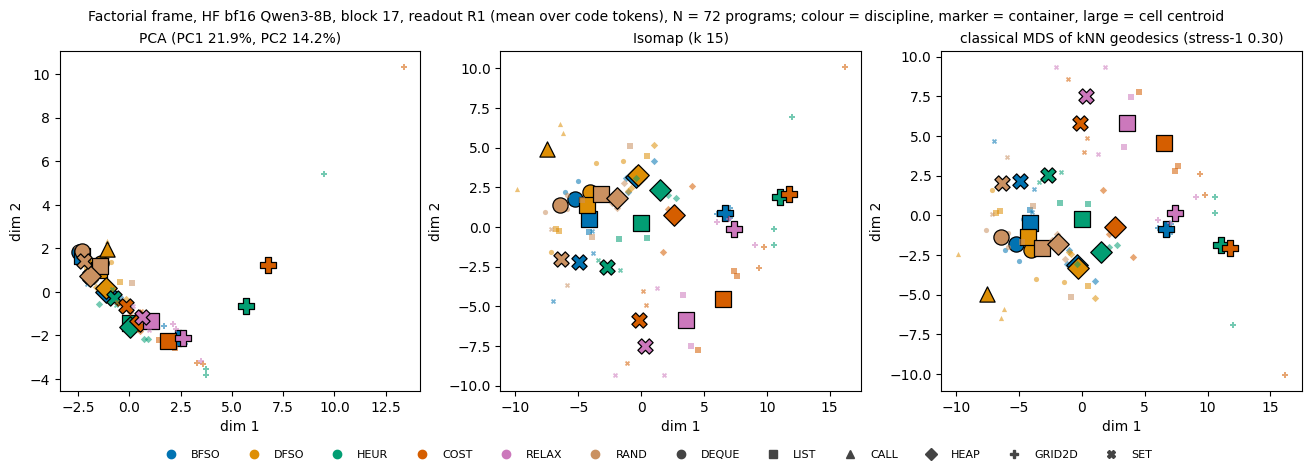

F1 ok


In [32]:
if "8b" in TAGS: run_fig("F1", lambda: fig_factorial("8b", "F1_factorial_8b"))

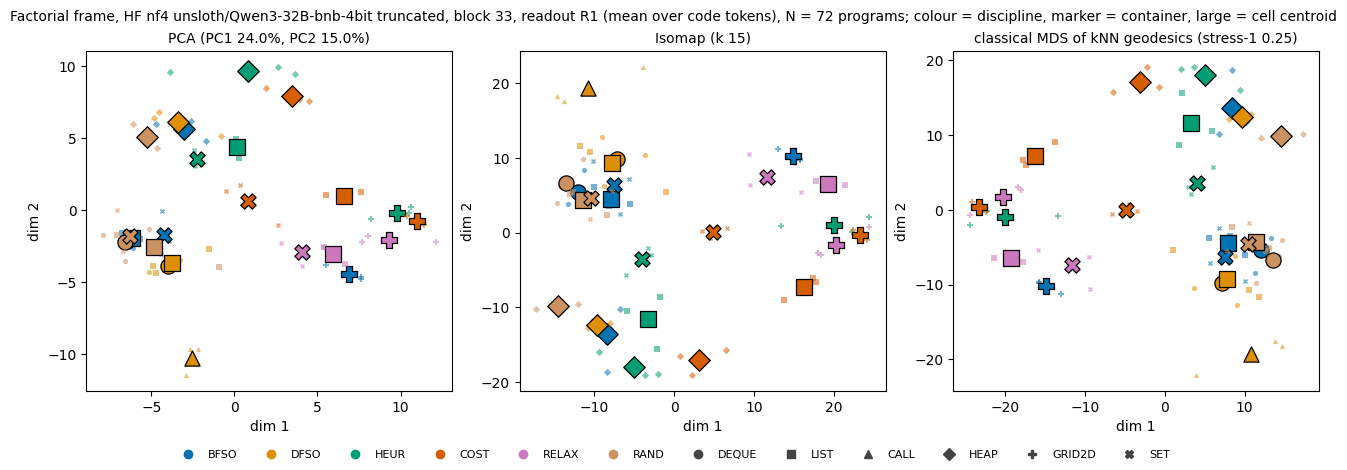

F2 ok


In [33]:
if "32b" in TAGS: run_fig("F2", lambda: fig_factorial("32b", "F2_factorial_32b"))

**F4: container-held-fixed frames (8B).** The frames are classical MDS of the kNN geodesics.
- In the HEAP frame (all heap-based cells), unit-weight Dijkstra (F-UD) and coordinate-key heaps (F-CK) are placed
  out of sample.
- In the GRID2D frame, Bellman-Ford (F-BF) and raster sweeps (F-RS) are placed.

Holding the container fixed isolates discipline.

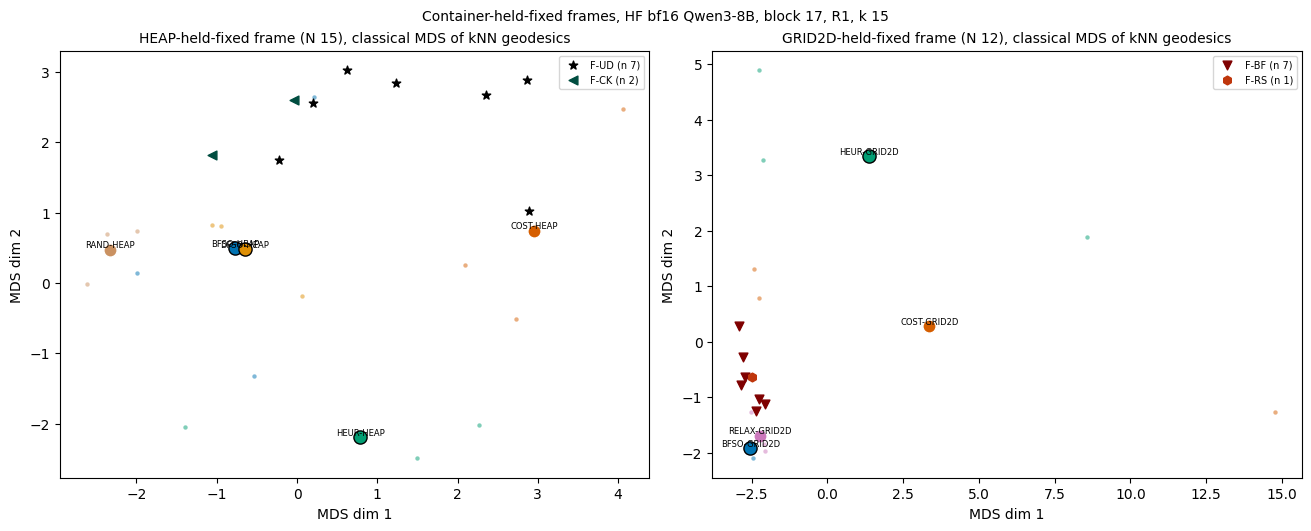

F4 ok


In [34]:
if "8b" in TAGS: run_fig("F4", lambda: fig_heldfixed("8b", "F4_heldfixed_8b"))

**F5: G1 bars.** ρ_dc (discipline | container) against ρ_cd (container | discipline), with program-bootstrap CIs and
the E0 / RANDNET baselines. The dashed line is the noise ceiling; the dotted line is the SUPPORTED threshold of
0.30.

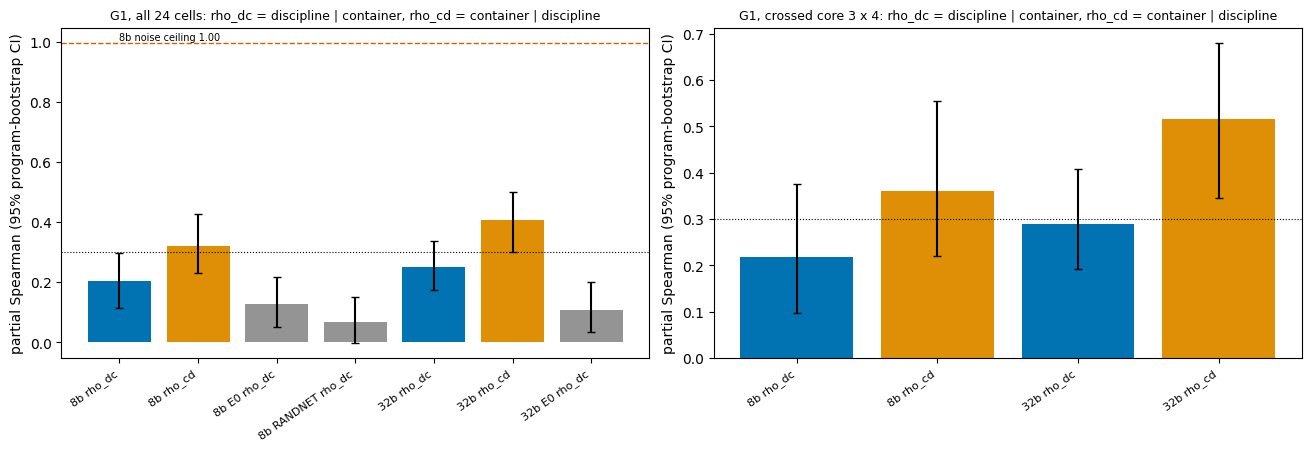

F5 ok


In [35]:
run_fig("F5", lambda: fig_g1_bars("F5_g1_bars"))

**F6: per-family g on the full frame.** The dashed line is the median non-banned class g: below it is EDGE (close to
the banned region), above it is OPPOSITE.

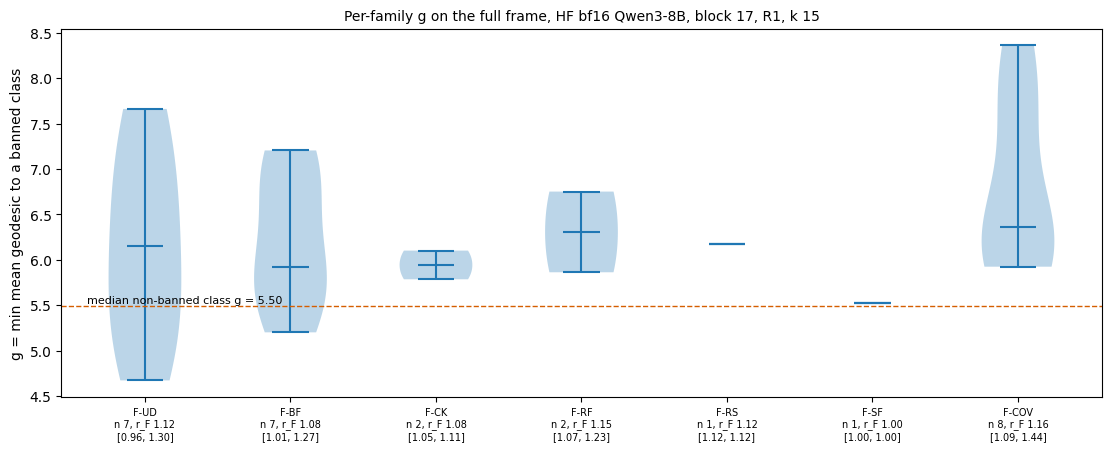

F6 8b ok


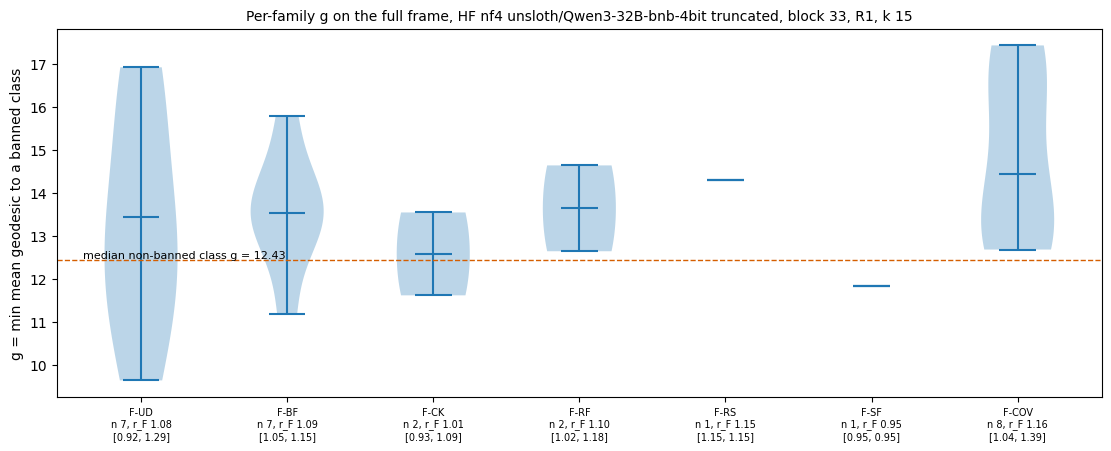

F6 32b ok


In [36]:
for tag, nm in (("8b", "F6_family_g_8b"), ("32b", "F6_family_g_32b")):
    if tag in TAGS: run_fig(f"F6 {tag}", lambda tag=tag, nm=nm: fig_violins(tag, nm))

**F7: the layer curve.** ρ_dc and ρ_cd at every extracted block, by relative depth. In the full run the curve was
flat: ρ_dc 0.20–0.26 on 8B and 0.25–0.30 on 32B.

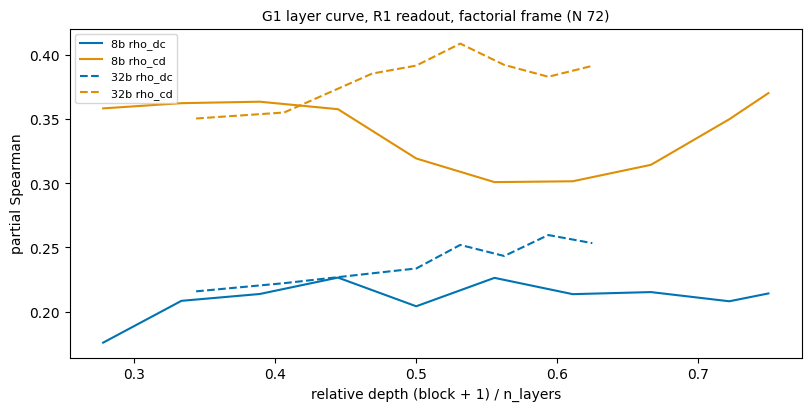

F7 ok


In [37]:
run_fig("F7", lambda: fig_layer("F7_layer_curve"))

**F8: placement heatmap (8B).** The share of each survivor family that lands nearest each frame class.

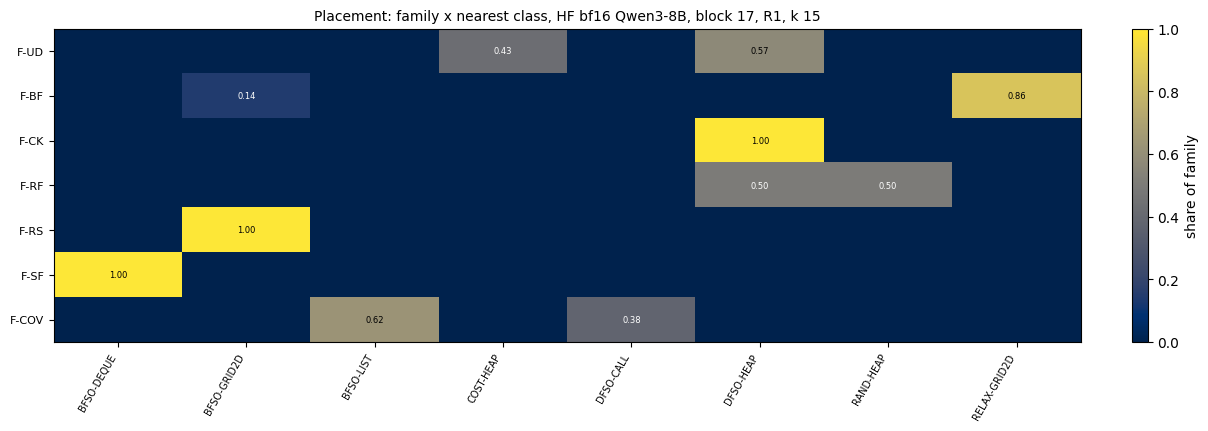

F8 ok


In [38]:
if "8b" in TAGS: run_fig("F8", lambda: fig_heatmap("8b", "F8_placement_heatmap_8b"))

## Results summary: demo vs full run

The table puts the demo's numbers beside the full run's (`full_run_reference` in the metadata).

| | demo | full run |
|---|---|---|
| factorial programs | 72 (3 per cell) | 287 |
| frame | 72 programs (cells only) | 464 programs (cells + catalogue) |
| placed programs | 28 | 351 |

With a quarter of the programs, the CIs are wider. The full-run frame also had catalogue classes, so the G2 shares
are comparable in direction only.

In [39]:
REF = META["full_run_reference"]


def _ci(lo_hi):
    return f"[{lo_hi[0]:.3f}, {lo_hi[1]:.3f}]"


table = []
for tag in TAGS:
    p, r, g, h = G1[tag]["primary"], REF[f"g1_{tag}"], G2[tag], REF[f"g2_{tag}"]
    sp, spr = G1[tag]["S2_rank_regression"]["semi_partial"], r["S2_semi_partial"]
    table += [
        (tag, "programs (factorial)", f"{p['n_programs']}", f"{r['n_programs']}"),
        (tag, "rho_dc  discipline | container", f"{p['rho_dc']:.3f} {_ci(p['bootstrap']['rho_dc']['ci95'])}",
         f"{r['rho_dc']:.3f} {_ci(r['rho_dc_ci95'])}"),
        (tag, "rho_cd  container | discipline", f"{p['rho_cd']:.3f} {_ci(p['bootstrap']['rho_cd']['ci95'])}",
         f"{r['rho_cd']:.3f} {_ci(r['rho_cd_ci95'])}"),
        (tag, "delta = rho_dc - rho_cd", f"{p['delta']:.3f} {_ci(p['bootstrap']['delta']['ci95'])}",
         f"{r['delta']:.3f} {_ci(r['delta_ci95'])}"),
        (tag, "restricted-perm p (dc / cd)", f"{p['perm_rho_dc']['p']:.4f} / {p['perm_rho_cd']['p']:.4f}",
         f"{r['perm_p_rho_dc']:.4f} / {r['perm_p_rho_cd']:.4f}"),
        (tag, "crossed core rho_dc / rho_cd",
         f"{G1[tag]['S1_crossed_core']['rho_dc']:.3f} / {G1[tag]['S1_crossed_core']['rho_cd']:.3f}",
         f"{r['core_rho_dc']:.3f} / {r['core_rho_cd']:.3f}"),
        (tag, "E0 bag-of-tokens rho_dc", f"{G1[tag]['S7_E0_bag_of_tokens']['rho_dc']:.3f}", f"{r['E0_rho_dc']:.3f}"),
    ]
    if "S7_RANDNET_block17" in G1[tag]:
        table.append((tag, "RANDNET rho_dc", f"{G1[tag]['S7_RANDNET_block17']['rho_dc']:.3f}",
                      f"{r['RANDNET_rho_dc']:.3f}"))
    table += [
        (tag, "S2 semi-partial surf / len / cont / disc",
         " / ".join(f"{sp[k]:.2f}" for k in ("D_surf", "D_len", "D_cont", "D_disc")),
         " / ".join(f"{spr[k]:.2f}" for k in ("D_surf", "D_len", "D_cont", "D_disc"))),
        (tag, "G2 frame class LOO accuracy (chance)",
         f"{g['frame_loo']['class_loo_accuracy']:.2f} ({g['frame_loo']['chance_class']:.3f})",
         f"{h['class_loo_accuracy']:.2f} ({h['chance_class']:.3f})"),
        (tag, "P-COV share nearest banned", f"{g['predictions']['P-COV']['share_nearest_banned']:.2f}",
         f"{h['P-COV_share_nearest_banned']:.2f}"),
        (tag, "P-BF share nearest RELAX", f"{g['predictions']['P-BF']['share_nearest_discipline_RELAX']:.2f}",
         f"{h['P-BF_share_nearest_RELAX']:.2f}"),
        (tag, "P-UD share nearest BFSO/COST",
         f"{g['predictions']['P-UD']['share_nearest_discipline_BFSO_or_COST']:.2f}",
         f"{h['P-UD_share_nearest_BFSO_or_COST']:.2f}"),
    ]
    for fam in ("F-UD", "F-BF", "F-COV"):
        d_, f_ = g["families_full"][fam], h["families_r_F"][fam]
        table.append((tag, f"{fam} r_F (verdict)", f"{d_['r_F']:.2f} ({d_['verdict']})",
                      f"{f_['r_F']:.2f} ({f_['verdict']})"))
    table.append((tag, "r_F placebo: random families EDGE",
                  f"{g['placebo_family_shuffle']['share_EDGE_full_frame']:.3f}", f"{h['placebo_share_EDGE']:.3f}"))
print(f"{'model':<6}{'quantity':<42}{'demo':<28}{'full run':<28}")
for row in table:
    print(f"{row[0]:<6}{row[1]:<42}{row[2]:<28}{row[3]:<28}")
print(f"\nG1 verdict: demo {VERDICT['verdict']} | full run {REF['g1_verdict']}")
print("demo why:", VERDICT["why"])

model quantity                                  demo                        full run                    
8b    programs (factorial)                      72                          287                         
8b    rho_dc  discipline | container            0.204 [0.116, 0.298]        0.226 [0.186, 0.265]        
8b    rho_cd  container | discipline            0.319 [0.233, 0.427]        0.300 [0.251, 0.351]        
8b    delta = rho_dc - rho_cd                   -0.115 [-0.243, 0.011]      -0.074 [-0.133, -0.018]     
8b    restricted-perm p (dc / cd)               0.0005 / 0.0005             0.0005 / 0.0005             
8b    crossed core rho_dc / rho_cd              0.219 / 0.360               0.280 / 0.366               
8b    E0 bag-of-tokens rho_dc                   0.127                       0.169                       
8b    RANDNET rho_dc                            0.066                       0.072                       
8b    S2 semi-partial surf / len / cont / disc  0.31 / 

**Where do the survivors land?** The summary figure has three panels:
- **left:** the G1 contrast for the demo and the full run;
- **centre and right:** each model's factorial frame in activation space (classical MDS of the kNN geodesics on the
  raw R1 states). Cell centroids are coloured by discipline, with marker = container and banned cells edged in
  black. The placed survivor programs are projected out of sample with Gower's formula, as in F4.

**Read the map by neighbourhood, not by the EDGE / OPPOSITE label.**
- The placebo row in the table shows that the label is set by the frame, not the family. Almost every random family
  of placed programs comes out OPPOSITE on this cells-only frame, just as every one came out EDGE on the full run's
  frame. Placed programs come from other prompts and several authors, so they sit farther from every frame program
  than the frame cells sit from each other.
- The family-specific evidence is which cell each program lands nearest to.

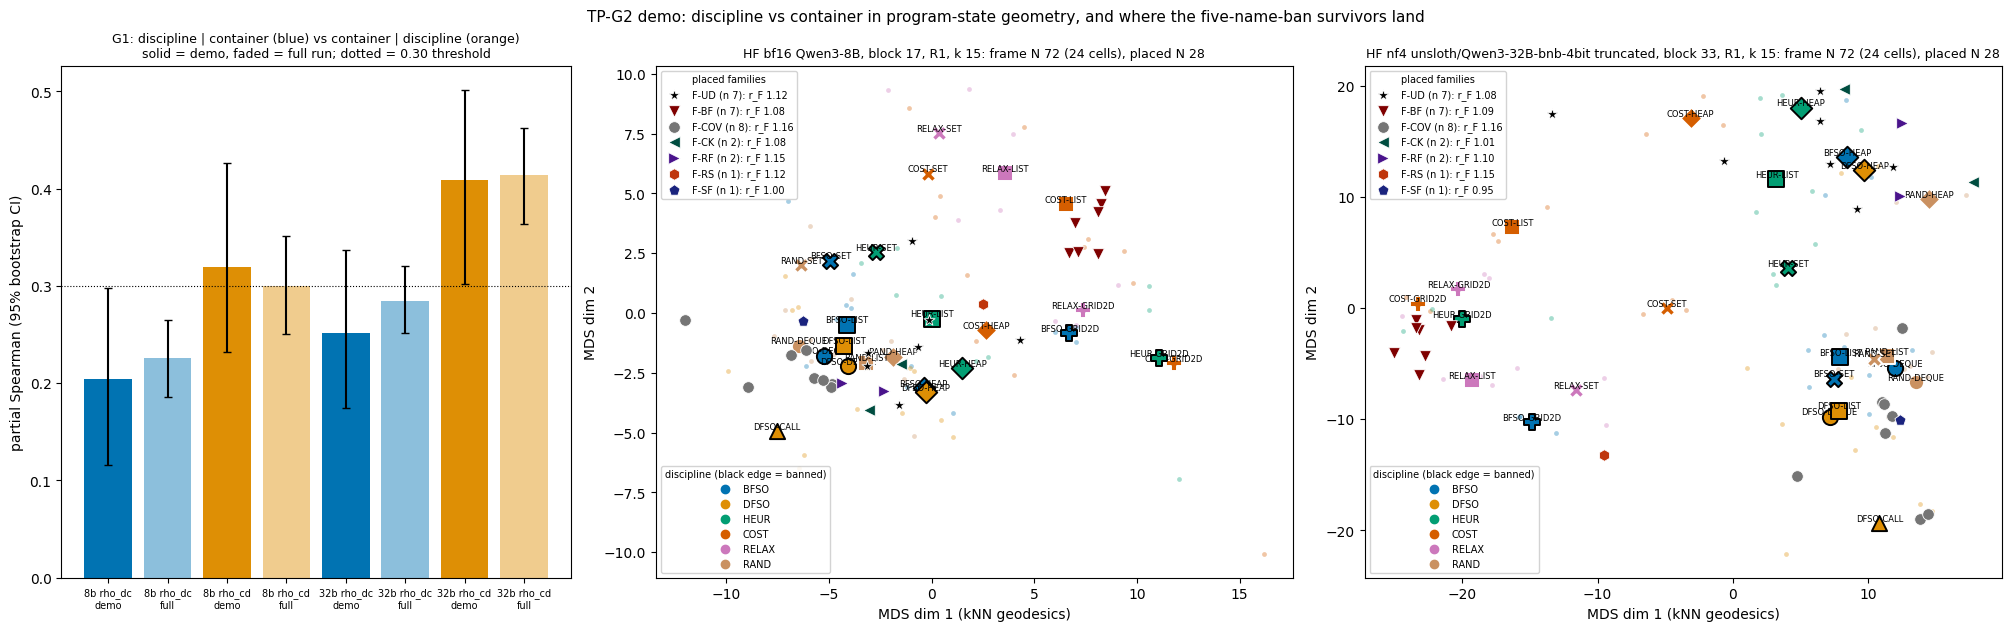

In [40]:
fig, axs = plt.subplots(1, 1 + len(TAGS), figsize=(6 + 7 * len(TAGS), 6.2), layout="constrained",
                        gridspec_kw={"width_ratios": [0.8] + [1.0] * len(TAGS)})
# ---- panel A: rho_dc vs rho_cd, demo vs full run
ax = axs[0]
labs, vals, err, cols = [], [], [], []
for tag in TAGS:
    p, r = G1[tag]["primary"], REF[f"g1_{tag}"]
    for stat, col in (("rho_dc", PALETTE[0]), ("rho_cd", PALETTE[1])):
        for src, v, ci, alpha in (("demo", p[stat], p["bootstrap"][stat]["ci95"], 1.0),
                                  ("full", r[stat], r[f"{stat}_ci95"], 0.45)):
            labs.append(f"{tag} {stat}\n{src}")
            vals.append(v)
            err.append([v - ci[0], ci[1] - v])
            cols.append(matplotlib.colors.to_rgba(col, alpha))
x = np.arange(len(vals))
ax.bar(x, vals, color=cols, yerr=np.clip(np.array(err).T, 0, None), capsize=3)
ax.axhline(0.30, color="black", lw=0.8, ls=":")
ax.set_xticks(x, labs, fontsize=7)
ax.set_ylabel("partial Spearman (95% bootstrap CI)")
ax.set_title("G1: discipline | container (blue) vs container | discipline (orange)\n"
             "solid = demo, faded = full run; dotted = 0.30 threshold", fontsize=9)
# ---- panels B, C: the factorial frame in activation space with the placed survivors (out-of-sample MDS)
for ax, tag in zip(axs[1:], TAGS):
    m = v10.MODELS[tag]
    full = analysis.build_full_frame(tag, m["primary_block"], 0, v10.K_PRIMARY)
    Xp, rows_p = analysis.placed(tag, m["primary_block"], 0)
    M = geometry.classical_mds(full.geo)
    n = len(full.X)
    D2 = full.geo ** 2
    J = np.eye(n) - 1.0 / n
    w, V = np.linalg.eigh(-0.5 * J @ D2 @ J)
    i2 = np.argsort(w)[::-1][:2]
    L = V[:, i2] / np.sqrt(np.maximum(w[i2], 1e-12))
    Mp = np.array([-0.5 * (g2.oos(x_, full.X, full.geo, full.k) ** 2 - D2.mean(1)) @ L for x_ in Xp])
    for c in full.classes:
        sel = full.labels == c
        col = DISC_COL.get(g2.disc_of(c), "#555555")
        ax.scatter(M[sel, 0], M[sel, 1], s=12, color=col, alpha=0.35, linewidths=0)
        cx, cy = M[sel].mean(0)
        ax.scatter([cx], [cy], s=120, marker=CONT_MK.get(g2.cont_of(c), "o"), color=col,
                   edgecolors="black" if g2.is_banned(c) else "white", linewidths=1.4, zorder=3)
        ax.annotate(c, (cx, cy), fontsize=6, ha="center", va="bottom")
    for f_ in ("F-UD", "F-BF", "F-COV", "F-CK", "F-RF", "F-RS", "F-SF"):
        sel = [i for i, r_ in enumerate(rows_p) if r_["family"] == f_]
        if sel:
            mk, col = FAM_MK[f_]
            ax.scatter(Mp[sel, 0], Mp[sel, 1], marker="o" if mk == "." else mk, s=70, color=col, edgecolors="white",
                       linewidths=0.6, zorder=5, label=f"{f_} (n {len(sel)}): r_F {G2[tag]['families_full'][f_]['r_F']:.2f}")
    hd = [plt.Line2D([], [], color=DISC_COL[d], marker="o", ls="", label=d) for d in DISCIPLINES]
    leg1 = ax.legend(fontsize=7, loc="upper left", title="placed families", title_fontsize=7, framealpha=0.85)
    ax.add_artist(leg1)
    ax.legend(handles=hd, fontsize=7, loc="lower left", title="discipline (black edge = banned)", title_fontsize=7,
              framealpha=0.85)
    ax.set_xlabel("MDS dim 1 (kNN geodesics)")
    ax.set_ylabel("MDS dim 2")
    ax.set_title(f"{m['engine']}, block {m['primary_block']}, R1, k {full.k}: frame N {n} (24 cells), placed N {len(Xp)}",
                 fontsize=9)
fig.suptitle("TP-G2 demo: discipline vs container in program-state geometry, and where the five-name-ban "
             "survivors land", fontsize=11)
fig.savefig(FIGS / "summary_demo.png", dpi=150)
plt.show()

## Takeaways and limits

**G1 (reproduced on a quarter of the programs).** Discipline *is* encoded:
- ρ_dc ≈ 0.20 / 0.25 (8B / 32B), with the permutation p at its 0.0005 floor;
- this is above the E0 bag-of-tokens (≈ 0.13 / 0.11) and RANDNET (≈ 0.07) baselines;
- the placebos fail as required.

But container is encoded more strongly (ρ_cd ≈ 0.32 / 0.41), and token surface and length dominate the rank
regression. The pre-registered verdict is therefore INDETERMINATE, as in the full run. The "path-search manifold"
mixes how a program searches with how it stores its frontier and how it is written.

**G2.** Survivor programs land next to the cells that share their mechanics:
- covert BFS / DFS land nearest a banned cell (8 / 8 on both models), and every covert BFS lands by a BFSO cell;
- grid Bellman-Ford lands nearest RELAX-GRID2D (6 / 7);
- unit-weight Dijkstra lands among the HEAP cells, always closer to BFSO/COST-HEAP than to HEUR-HEAP (the
  pre-registered contrast). Yet 4 of 7 land nearest DFSO-HEAP: storage again pulls harder than search order.

A name ban **substitutes** a nearby mechanism rather than escaping the region. The EDGE / OPPOSITE verdict (r_F) is
not family-specific on either frame; see the placebo row.

**Limits.**
- Geometry is correlational: nothing here steers a model. Iteration 7's in-manifold pushes moved 0/300 outputs.
- Every factorial program has one author (Qwen3-32B), while the placed programs come from several models.
- This demo uses a quarter of the factorial programs, a frame without catalogue classes and 28 of the 351 placed
  programs.

**Full scale.** Run the experiment's `method.py all-analysis` with its `cache/states_v10/`. That cache is kept on
the run's volume and is not part of the published repository.